# Argon reference and covariance correction — AcH delay scans
FLASH2 · beamtime 11024642. Companion to `inspect_delay_scan_acet_updated.ipynb`.

Eight tests: (1) electron yield, (2) Ar–Ar covariance, (3) covariance ratio and intensity scaling, (4) Ar-gated covariance, (5) energy stability, (6) partial covariance on Ar, (7) multiple monitors, (8) template subtraction.

Run from the repository root or `analysis/notebooks`. Set the file selection and gates below, then run in order. Start with short scans at one photon energy. All gates are **candidate windows**, not confirmed species assignments. The Ar 2p photoelectron gate should move with photon energy; the normal Auger gate is approximately fixed. Inspect the spectrum and covariance islands before interpreting traces.

`MONITOR`, `USE_READY`, `TAU_NS` affect electron yields only. All covariance uses **recorded** shot moments; dead-time exclusion removes pair pixels, not missed pairs. Covariance is not true coincidence. The Ar 2p–Auger channel is a candidate reference, not guaranteed static. A gate used for partial covariance cannot independently validate that correction. No smoothing or interpolation of delay traces is applied. No files are modified.

In [203]:
import sys
from pathlib import Path
import h5py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

repo = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'analysis/scripts/config.py').is_file())
scripts = str(repo / 'analysis/scripts')
if scripts not in sys.path:
    sys.path.insert(0, scripts)
from config import COMBINED_DIR
import calibration

# ---- Data selection -----------------------------------------------------
PHOTON_ENERGY = 268       # eV; keep in agreement with the selected files
SCAN_PATTERN = 'Ethanol_delay_scan_short_*_268eV_*_aggregates_tr.h5'
SCAN_PATTERN = 'AcH_long_delay_scan_*_269.7eV_*_aggregates_tr.h5'
# Explicitly select the three scans in the source notebook by default.
# FILES = [COMBINED_DIR / name for name in [
#     'AcH_short_delay_scan_2_268.2eV_2810107042_aggregates_tr.h5',
#     'AcH_short_delay_scan_3_268.2eV_2810120192_aggregates_tr.h5',
#     'AcH_short_delay_scan_4_268.2eV_2810135905_aggregates_tr.h5',
# ]]
FILES = sorted(COMBINED_DIR.glob(SCAN_PATTERN))
# FILES = FILES[-1:]
VLS_CAL_FILE = COMBINED_DIR / 'run60612_AcH_undulator_scan_part2_265-280eV_2809782740.h5'
GMD_BINS = None             # indices into each file's own percentile bins
FS_PER_STAGE_UNIT = 0.349 / 1000
Z_ZERO = 0
DELAY_SIGN = 1
DELAY_BASELINE = None       # None: all delays; or (lo, hi) fs
SCAN_MINUTES = {}
TRAIN_RATE = 10
NORMALISE = 'per_uJ'        # candidate ion yield: 'per_uJ' or 'per_shot'
MONITOR = 'vls'             # 'vls', 'gmd', 'shot' for electron yields
USE_READY = False
TAU_NS = 6
MIN_SHOTS = 100

# ---- Argon and molecular gates ------------------------------------------
# Broad starting gate around the neutral Ar 2p doublet; adjust after inspection.
AR_PHOTO = (PHOTON_ENERGY - 253.2, PHOTON_ENERGY - 245.2)
AR_AUGER = (200, 208)
AR_ION = (19, 21)           # candidate Ar2+; may overlap AcH fragments
AR_CONDITION = AR_PHOTO     # recorded electron count per shot for partial covariance
# Optional independent control pair; must not overlap AR_CONDITION.
# Set only after identifying a suitable peak; no assignment is assumed.
HOLDOUT_EE = None           # e.g. ((lo1, hi1), (lo2, hi2))
HOLDOUT_EI = None           # e.g. ((lo_e, hi_e), (lo_mq, hi_mq))
EE_ROIS = [((242, 246), (180, 200)), ((242, 246), (200, 210)), ((246, 249), (210, 220)), ((246, 249), (220, 230)),
           ((246, 249), (180, 200)), ((246, 249), (200, 210)),
           ((250, 260), (180, 200))]
EI_ROIS = [((220, 240), (0.5, 1.5)), ((220, 240), (12, 16)),
           ((220, 240), (19, 21)), ((220, 240), (27, 32)),
           ((220, 240), (43, 45))]
YIELD_WINDOWS = [AR_PHOTO, AR_AUGER, (242, 246), (250, 260)]
# Local background density for peak centroid/width. None = no subtraction.
PHOTO_SIDEBANDS = None      # set two clean neighbouring windows after inspection
AUGER_SIDEBANDS = None

# ---- Covariance --------------------------------------------------------
COV_FILES = FILES
COV_GMD_BINS = GMD_BINS
REBIN_E = 1
REBIN_I = 2
MIN_COV_SHOTS = 300
DEAD_TIME_NS = 6.0          # TOF centre separation, matches source section 9.1
WINDOW_EST = 'partial on GMD'
RUN_VLS_COV = True
RUN_AR_COV = True
RUN_MULTI_COV = True
COMMON_COV_SELECTION = True # compare methods using identical accepted cells
MONITOR_COND_MAX = 1e6       # condition number of standardised monitor covariance
GMD_VLS_MOMENT = 'AtG'      # candidate key; verify it stores <A G> (not centred covariance)
MAX_MATRIX_MB = 1800         # guard before allocating time-resolved matrices
COV_DELAY_WINDOW = None     # delay-integrated maps / intensity diagnostic only
COV_NORMALISE_GMD = True    # optional display scaling; not a nonlinear correction
COV_DENSITY = True          # gated spectra only; ROIs always integrate counts/bin
CLIP_PCT = 99.5
COV_KE_LIM = (0, 290)
COV_MQ_LIM = (0, 50)
CROSS_KE_LIM = (150, 275)
RATIO_POWER = 1.0           # 1 = simple ratio; change only after checking scaling
RATIO_MIN_FRACTION = 0.2    # mask reference < fraction of positive baseline
INTENSITY_MONITOR = 'gmd'   # diagnostic across intensity bins: 'gmd' or 'vls'

# ---- Template subtraction (opt-in) --------------------------------------
AR_TEMPLATE_FILE = None     # Path to pure-Ar aggregate at matching photon energy/settings
TEMPLATE_COMPATIBLE = False # set True only after verifying energy, detector, FEL, gas conditions
TEMPLATE_EST = 'partial on GMD' # 'within GMD bins', 'partial on GMD' or 'partial on VLS'
TEMPLATE_SUBTRACT_EI = False # requires independent EI efficiency/relative scaling validation
TEMPLATE_MIN_REF = 0.0      # minimum positive target reference covariance (per shot)

print(f'{len(FILES)} files selected:')
for path in FILES:
    print(path.name)

3 files selected:
AcH_long_delay_scan_1_269.7eV_2810289120_aggregates_tr.h5
AcH_long_delay_scan_2_269.7eV_2810315452_aggregates_tr.h5
AcH_long_delay_scan_3_269.7eV_2810342023_aggregates_tr.h5


## 0. Load data and calibrated axes
Same first-moment loading and calibration as the source. Pool sums and exposures before division. Select compatible delay and TOF edges; long and short scans should normally be analysed separately.

In [204]:
# Read only the first moments and bin edges. D, C and G are means per shot.
if not FILES:
    raise FileNotFoundError('No delay aggregates found in ' + str(COMBINED_DIR))

scans = {}
axes = {}
for path in FILES:
    path = Path(path)
    with h5py.File(path, 'r') as f:
        if f.attrs['config'] != 1 or f.attrs['mode'] != 'time_resolved':
            raise ValueError(f'{path.name}: expected config 1 time_resolved aggregates')
        edges = {key: f[key][:] for key in ('z_edges', 'tof_edges', 'ion_tof_edges')}
        if not axes:
            axes = edges
        elif any(not np.array_equal(edges[key], axes[key]) for key in axes):
            raise ValueError(f'{path.name}: different delay or TOF edges. Select compatible scans.')

        n = f['n_per_bin'][:]
        D, C, G = f['D'][:], f['C'][:], f['G'][:]
        gmd_edges = f['gmd_edges'][:]
        attrs = dict(f.attrs)

    # Empty cells contain NaNs. Ignore them, not NaNs in populated cells.
    if any(not np.isfinite(a[n > 0]).all() for a in (D, C, G)):
        raise ValueError(f'{path.name}: non-finite means in populated bins')
    bins = slice(None) if GMD_BINS is None else GMD_BINS
    n, D, C, G = n[bins], D[bins], C[bins], G[bins]
    # Convert means to sums before collapsing the GMD dimension.
    e = np.where(n[..., None] > 0, D, 0) * n[..., None]
    i = np.where(n[..., None] > 0, C, 0) * n[..., None]
    g = np.where(n > 0, G, 0) * n

    # Acquisition duration: read just the two train-ID endpoints.
    minutes = SCAN_MINUTES.get(path.name, np.nan)
    source = Path(attrs.get('input_h5', ''))
    if not source.is_absolute():
        source = repo / source
    if not source.is_file():
        source = COMBINED_DIR / path.name.replace('_aggregates_tr.h5', '.h5')
    if not np.isfinite(minutes) and source.is_file():
        with h5py.File(source, 'r') as f:
            if 'tID' in f and len(f['tID']):
                minutes = (int(f['tID'][-1]) - int(f['tID'][0]) + 1) / TRAIN_RATE / 60

    scans[path.name] = dict(n=n.sum(axis=0), e=e.sum(axis=0),
                            i=i.sum(axis=0), g=g.sum(axis=0),
                            minutes=minutes, gmd_edges=gmd_edges, attrs=attrs)
    s = scans[path.name]
    print(f'\n{path.name}')
    print(f'  shots = {s["n"].sum():,}; e = {s["e"].sum():,.0f}; i = {s["i"].sum():,.0f}')
    print(f'  occupied delay bins = {np.count_nonzero(s["n"])} / {len(s["n"])}; time = {minutes:.1f} min')
    print('  GMD edges (uJ):', np.round(gmd_edges, 3))
    print('  skipped z outside / NaN:', attrs.get('n_skipped_z_oor', '?'), attrs.get('n_skipped_z_nan', '?'))
    print('  skipped max hits:', attrs.get('n_skipped_max_hits', '?'))

# GMD percentile edges can differ by file. Pool counts, not means.
combined = {key: np.sum([s[key] for s in scans.values()], axis=0)
            for key in ('n', 'e', 'i', 'g')}
combined['minutes'] = sum(s['minutes'] for s in scans.values())
scans_raw, combined_raw = scans, combined
if GMD_BINS is not None:
    print("Note: selected GMD indices refer to each scan's own edges.")


AcH_long_delay_scan_1_269.7eV_2810289120_aggregates_tr.h5
  shots = 2,459,088; e = 2,894,754; i = 1,299,142
  occupied delay bins = 32 / 32; time = 41.8 min
  GMD edges (uJ): [0.02  0.109 0.207 0.346 0.583 4.446]
  skipped z outside / NaN: 0 0
  skipped max hits: 38

AcH_long_delay_scan_2_269.7eV_2810315452_aggregates_tr.h5
  shots = 2,457,818; e = 2,840,521; i = 1,287,355
  occupied delay bins = 32 / 32; time = 41.8 min
  GMD edges (uJ): [0.02  0.106 0.201 0.335 0.563 4.439]
  skipped z outside / NaN: 0 0
  skipped max hits: 501

AcH_long_delay_scan_3_269.7eV_2810342023_aggregates_tr.h5
  shots = 2,453,743; e = 2,778,720; i = 1,242,309
  occupied delay bins = 32 / 32; time = 41.8 min
  GMD edges (uJ): [0.02  0.102 0.195 0.325 0.546 4.597]
  skipped z outside / NaN: 0 0
  skipped max hits: 48


In [205]:
if DELAY_SIGN not in (-1, 1):
    raise ValueError('DELAY_SIGN must be +1 or -1')

z_edges = axes['z_edges']
delay_edges = DELAY_SIGN * (z_edges - Z_ZERO) * FS_PER_STAGE_UNIT
ke_edges = calibration.ke_of_tof(axes['tof_edges'] / 10)[::-1]
mq_edges = calibration.mq_of_tof(axes['ion_tof_edges'] / 10)

# Keep all plotted axes increasing. Copy dictionaries so this cell can be rerun.
scans = {name: dict(s) for name, s in scans_raw.items()}
combined = dict(combined_raw)
for s in [*scans.values(), combined]:
    s['e'] = s['e'][:, ::-1]
    if DELAY_SIGN == -1:
        for key in ('n', 'e', 'i', 'g'):
            s[key] = s[key][::-1]
if DELAY_SIGN == -1:
    delay_edges = delay_edges[::-1]

delay = (delay_edges[:-1] + delay_edges[1:]) / 2
ke = (ke_edges[:-1] + ke_edges[1:]) / 2
mq = (mq_edges[:-1] + mq_edges[1:]) / 2
dke, dmq = np.diff(ke_edges), np.diff(mq_edges)

if any(np.any(~np.isfinite(edges)) or np.any(np.diff(edges) <= 0)
       for edges in (delay_edges, ke_edges, mq_edges)):
    raise ValueError('Calibrated edges must be finite and increasing')

# Safe division: empty exposure gives NaN, not zero signal.
def divide(a, b):
    a, b = np.broadcast_arrays(a, b)
    return np.divide(a, b, out=np.full(a.shape, np.nan, dtype=float), where=b > 0)

exposure_key = {'per_uJ': 'g', 'per_shot': 'n'}[NORMALISE]
unit = {'per_uJ': r'$\mu$J', 'per_shot': 'shot'}[NORMALISE]

print(f'Delay: {delay_edges[0]:.3f} to {delay_edges[-1]:.3f} fs, {len(delay)} bins')
print('Delay bin widths (fs):', np.unique(np.round(np.diff(delay_edges), 6)))
print(f'KE: {ke_edges[0]:.2f} to {ke_edges[-1]:.2f} eV')
print(f'm/q: {mq_edges[0]:.2f} to {mq_edges[-1]:.2f} u/e')

Delay: -4.889 to 59.333 fs, 32 bins
Delay bin widths (fs): [2.006968]
KE: 1.00 to 290.29 eV
m/q: 0.21 to 50.43 u/e


In [206]:
if DELAY_BASELINE is None:
    ref_mask = np.ones(len(delay), dtype=bool)
else:
    lo, hi = DELAY_BASELINE
    ref_mask = (delay >= lo) & (delay < hi)

if not ref_mask.any():
    raise ValueError('No bins in the selected delay reference')

def delay_reference(counts, exposure):
    return divide(counts[ref_mask].sum(axis=0),
                  exposure[ref_mask].sum())

idx = np.flatnonzero(ref_mask)
print(f'Reference: {delay_edges[idx[0]]:.2f} to '
      f'{delay_edges[idx[-1]+1]:.2f} fs')

Reference: -4.89 to 59.33 fs


In [207]:
# ---- Load VLS aggregates --------------------------------------------------


vls_scans = {}
vls_pixels = None

for path in FILES:

    path = Path(path)

    with h5py.File(path, 'r') as f:

        if 'A' not in f:
            raise ValueError(f'{path.name}: no VLS aggregates stored')

        n = f['n_per_bin'][:]
        A = f['A'][:]
        pixels = f['vls_pixels'][:]

        if vls_pixels is None:
            vls_pixels = pixels
        else:
            np.testing.assert_array_equal(vls_pixels, pixels)

        np.testing.assert_array_equal(f['z_edges'][:], z_edges)

        if A.shape != (*n.shape, len(pixels)):
            raise ValueError(f'{path.name}: incompatible VLS shape')
        print(path.name, '| VLS shape:', A.shape)

    if not np.isfinite(A[n > 0]).all():
        raise ValueError(f'{path.name}: non-finite VLS means')

    # Same GMD selection as the electron and ion analysis.
    bins = slice(None) if GMD_BINS is None else GMD_BINS
    n, A = n[bins], A[bins]

    # Convert means to sums before collapsing the GMD axis.
    a = np.where(n[..., None] > 0, A, 0) * n[..., None]

    a = a.sum(axis=0)
    n = n.sum(axis=0)

    if DELAY_SIGN == -1:
        a, n = a[::-1], n[::-1]

    np.testing.assert_array_equal(n, scans[path.name]['n'])

    vls_scans[path.name] = dict(
        a=a,
        n=n,
        g=scans[path.name]['g']
    )

# Pool sums across scans.
vls_combined = {
    key: np.sum([s[key] for s in vls_scans.values()], axis=0)
    for key in ('a', 'n', 'g')
}

AcH_long_delay_scan_1_269.7eV_2810289120_aggregates_tr.h5 | VLS shape: (5, 32, 380)
AcH_long_delay_scan_2_269.7eV_2810315452_aggregates_tr.h5 | VLS shape: (5, 32, 380)
AcH_long_delay_scan_3_269.7eV_2810342023_aggregates_tr.h5 | VLS shape: (5, 32, 380)


In [208]:
# Load the ready files (if present) independently of USE_READY.
# Keep full GMD resolution for the correction diagnostics and section 7.3.
ready_scans = {}
electron_scans = {}
all_ready = True
bins = slice(None) if GMD_BINS is None else GMD_BINS

electron_exposure_key = {'vls': 'm', 'gmd': 'g', 'shot': 'n'}[MONITOR]
electron_unit = {'vls': '10⁴ ADU', 'gmd': r'$\mu$J', 'shot': 'shot'}[MONITOR]
electron_label = f'{"Corrected" if USE_READY else "Recorded"} | {MONITOR}'
if USE_READY:
    electron_label += f' | τ = {TAU_NS:g} ns'

for path in FILES:
    s = scans[path.name]
    with h5py.File(path, 'r') as f:
        n = f['n_per_bin'][:]
        D = f['D'][:]
        G = f['G'][:]
        M = f['A'][:].sum(axis=-1) / 1e4
        gmd_edges = f['gmd_edges'][:]

    # M is the mean VLS line sum per shot, not the GMD bin centre.
    m = vls_scans[path.name]['a'].sum(axis=1) / 1e4
    s_e = dict(n=s['n'], g=s['g'], m=m, e_recorded=s['e'],
               e_corrected=None, e=s['e'])
    if np.any((n > 0) & (M <= 0)):
        print(f'{path.name}: warning: non-positive VLS means in populated cells')
    if np.any((s['n'] > 0) & (~np.isfinite(m) | (m <= 0))):
        raise ValueError(f'{path.name}: non-positive/non-finite pooled VLS exposure; check VLS data')

    ready_path = path.with_name(path.stem + '_ready.h5')
    r = dict(n=n, D=D, G=G, M=M, gmd_edges=gmd_edges)
    ready_scans[path.name] = r
    if not ready_path.is_file():
        all_ready = False
        print(f'Missing: {ready_path.name}')
        electron_scans[path.name] = s_e
        continue

    with h5py.File(ready_path, 'r') as f:
        np.testing.assert_array_equal(f['n_per_bin'][:], n)
        np.testing.assert_array_equal(f['tof_edges'][:], axes['tof_edges'])
        for key, expected in [('z_edges', z_edges), ('gmd_edges', gmd_edges)]:
            if key in f:
                np.testing.assert_array_equal(f[key][:], expected)
        np.testing.assert_allclose(f['D'][:], D, rtol=1e-10, atol=1e-12, equal_nan=True)
        taus = f['taus_ns'][:]
        if f['D_live'].shape != (len(taus), *D.shape):
            raise ValueError(f'{ready_path.name}: incompatible D_live shape')
        if not bool(f.attrs.get('check_n_equal', True)):
            raise ValueError(f'{ready_path.name}: failed shot-count check')
    r.update(taus=taus)
    tau_idx = np.flatnonzero(np.isclose(taus, TAU_NS))
    if len(tau_idx) != 1:
        all_ready = False
        print(f'{ready_path.name}: τ = {TAU_NS} ns unavailable; stored values: {taus}')
    else:
        with h5py.File(ready_path, 'r') as f:
            Dm = f['D_live'][tau_idx[0]]
        r['Dm'] = Dm
        if not np.isfinite(Dm[bins][n[bins] > 0]).all() or np.any(Dm[bins][n[bins] > 0] < 0):
            all_ready = False
            print(f'{ready_path.name}: invalid corrected means in selected populated cells')
        else:
            e = (np.where(n[bins][..., None] > 0, Dm[bins], 0)
                 * n[bins][..., None]).sum(axis=0)[:, ::-1]
            if DELAY_SIGN == -1:
                e = e[::-1]
            s_e['e_corrected'] = e
            if USE_READY:
                s_e['e'] = e
            print(f'{ready_path.name}: validated; τ = {TAU_NS:g} ns')
    electron_scans[path.name] = s_e

if USE_READY and not all_ready:
    raise ValueError('USE_READY=True requires valid corrected means for every selected scan. '
                     'Generate/check the ready files or set USE_READY=False.')

# Pool counts and exposure before division. Never average normalised curves.
electron_combined = {key: np.sum([s[key] for s in electron_scans.values()], axis=0)
                     for key in ('n', 'g', 'm', 'e_recorded', 'e')}
if all_ready:
    electron_combined['e_corrected'] = np.sum(
        [s['e_corrected'] for s in electron_scans.values()], axis=0)
else:
    electron_combined['e_corrected'] = None
print('Main electron analysis:', electron_label)

AcH_long_delay_scan_1_269.7eV_2810289120_aggregates_tr_ready.h5: validated; τ = 6 ns
AcH_long_delay_scan_2_269.7eV_2810315452_aggregates_tr_ready.h5: validated; τ = 6 ns
AcH_long_delay_scan_3_269.7eV_2810342023_aggregates_tr_ready.h5: validated; τ = 6 ns
Main electron analysis: Recorded | vls


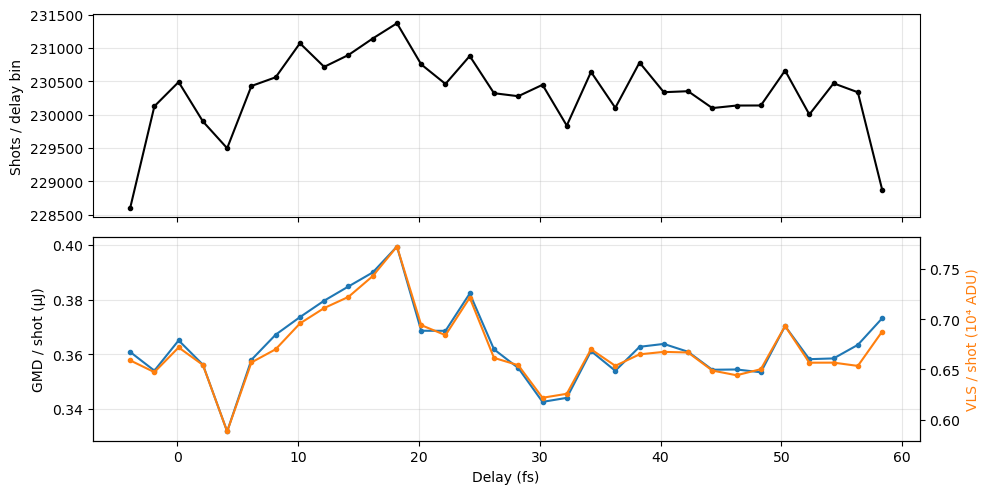

In [209]:
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax[0].plot(delay, combined['n'], 'k.-')
ax[0].set_ylabel('Shots / delay bin')
ax[1].plot(delay, divide(combined['g'], combined['n']), '.-', label='GMD (µJ)')
a = ax[1].twinx()
a.plot(delay, divide(electron_combined['m'], combined['n']), 'C1.-', label='VLS')
ax[1].set(ylabel='GMD / shot (µJ)', xlabel='Delay (fs)')
a.set_ylabel('VLS / shot (10⁴ ADU)', color='C1')
for a in ax:
    a.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## 1. Argon electron yield reference
First inspect the gates. Show recorded and ready-corrected yields for the chosen monitor, then compare GMD, VLS and per-shot normalisation. Relative traces use the exposure-weighted reference interval. A flat yield does not prove a flat covariance.

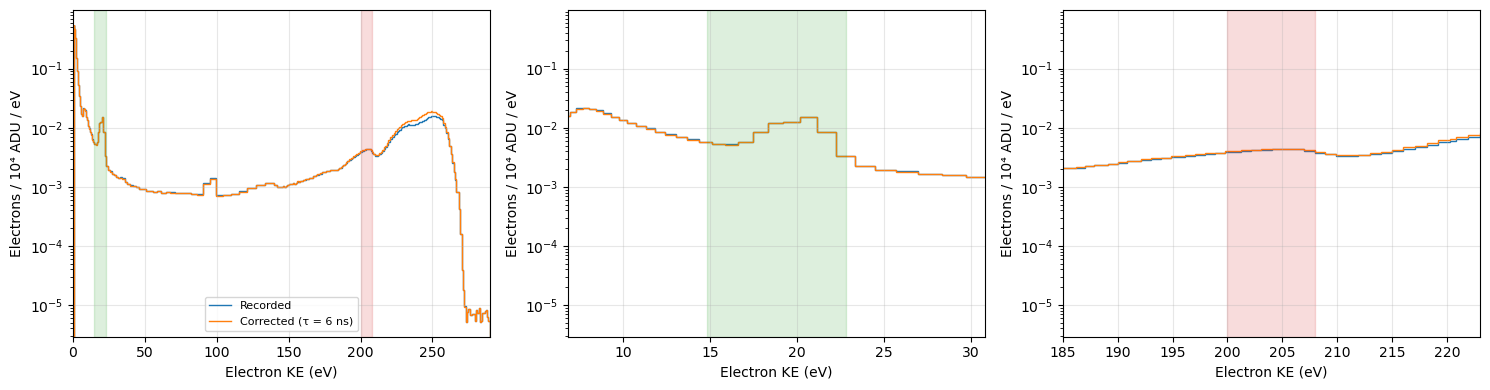

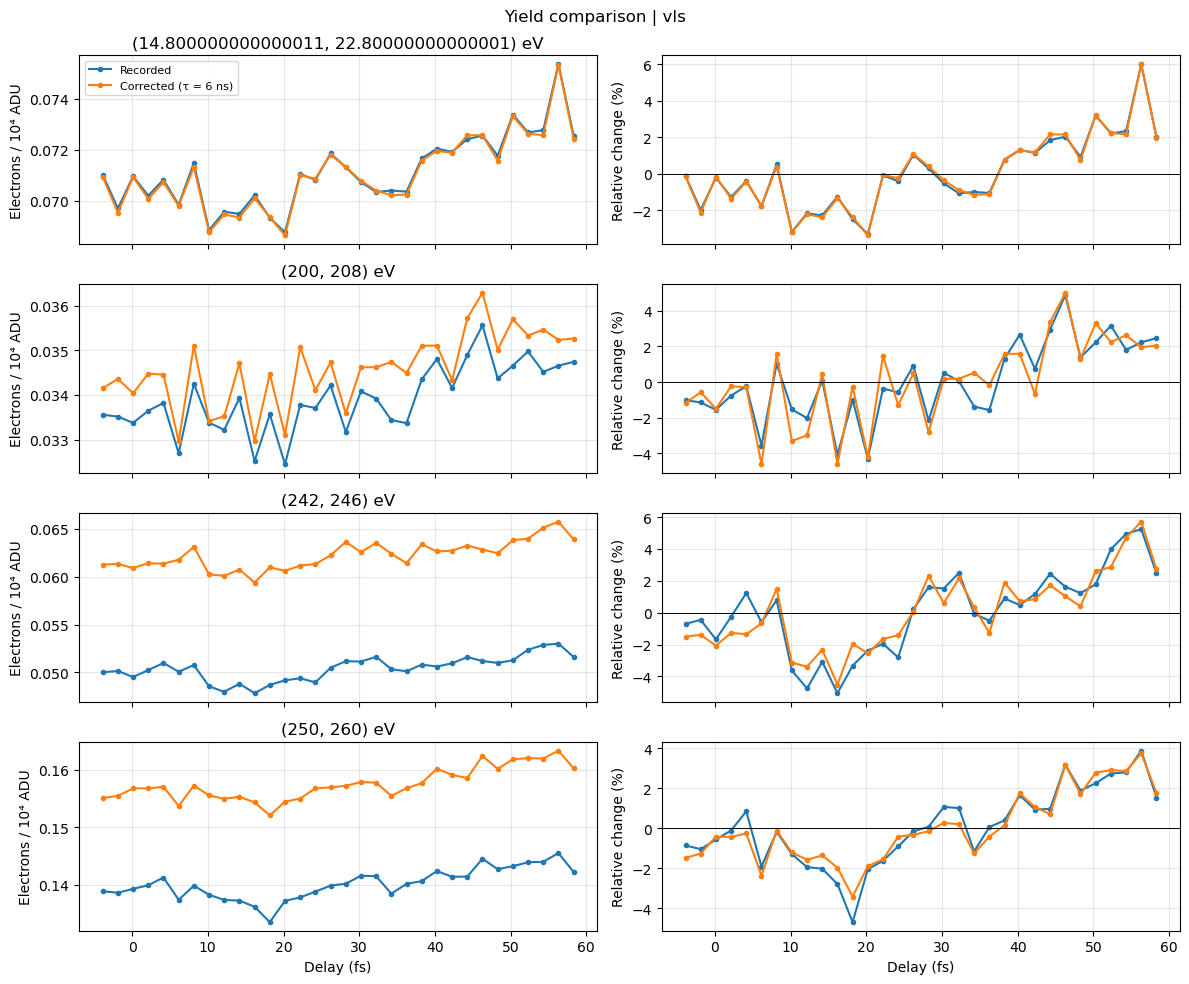

In [210]:
def in_win(centres, lo, hi):
    return (centres >= lo) & (centres < hi)

curves = [('Recorded', electron_combined['e_recorded'])]
if all_ready:
    curves.append((f'Corrected (τ = {TAU_NS:g} ns)', electron_combined['e_corrected']))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for label, e in curves:
    y = divide(e.sum(axis=0), electron_combined[electron_exposure_key].sum()) / dke
    for a, lim in zip(ax, [COV_KE_LIM, (max(0, AR_PHOTO[0]-8), AR_PHOTO[1]+8),
                           (AR_AUGER[0]-15, AR_AUGER[1]+15)]):
        a.stairs(y, ke_edges, label=label)
        a.set(xlim=lim, yscale='log', xlabel='Electron KE (eV)', ylabel=f'Electrons / {electron_unit} / eV')
for a in ax:
    for j, win in enumerate([AR_PHOTO, AR_AUGER]):
        a.axvspan(*win, color=f'C{j+2}', alpha=0.16)
    a.grid(alpha=0.3)
ax[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(len(YIELD_WINDOWS), 2, figsize=(12, 2.5*len(YIELD_WINDOWS)),
                       sharex=True, squeeze=False)
for j, win in enumerate(YIELD_WINDOWS):
    gate = in_win(ke, *win)
    if not gate.any():
        raise ValueError(f'Empty electron yield gate {win}')
    for label, e in curves:
        counts = e[:, gate].sum(axis=1)
        exposure = electron_combined[electron_exposure_key]
        y = divide(counts, exposure)
        y[electron_combined['n'] < MIN_SHOTS] = np.nan
        ref = delay_reference(counts, exposure)
        ax[j, 0].plot(delay, y, '.-', label=label)
        ax[j, 1].plot(delay, 100*(divide(y, ref)-1), '.-', label=label)
    ax[j, 0].set(title=f'{win} eV', ylabel=f'Electrons / {electron_unit}')
    ax[j, 1].set_ylabel('Relative change (%)')
    ax[j, 1].axhline(0, color='k', lw=0.7)
for a in ax.flat:
    a.grid(alpha=0.3)
for a in ax[-1]:
    a.set_xlabel('Delay (fs)')
ax[0, 0].legend(fontsize=8)
fig.suptitle(f'Yield comparison | {MONITOR}')
fig.tight_layout()
plt.show()

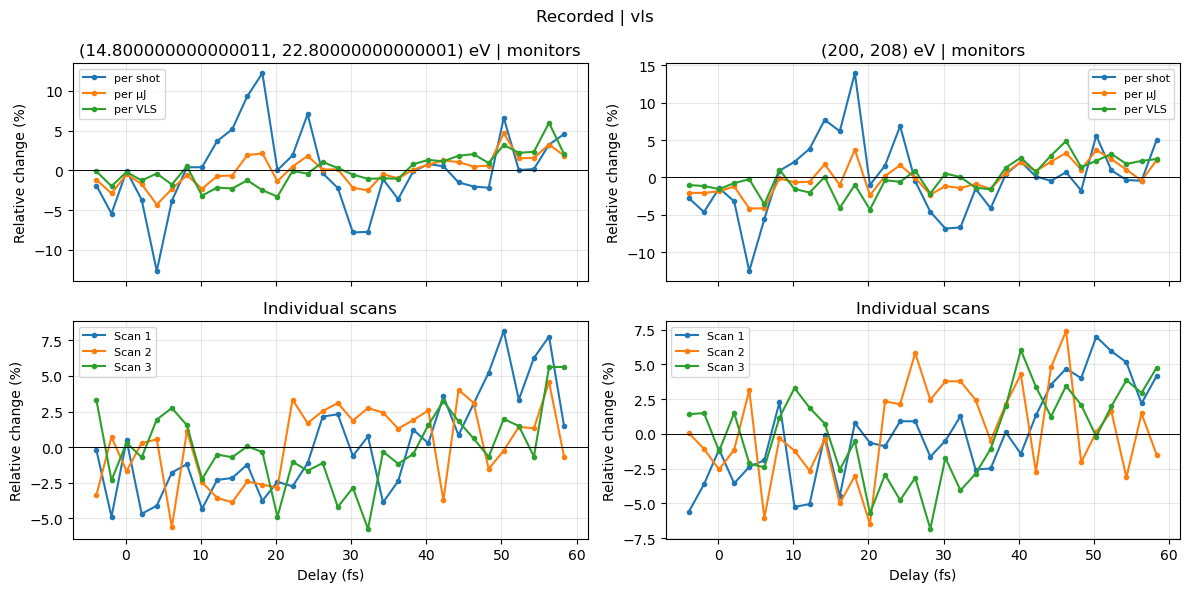

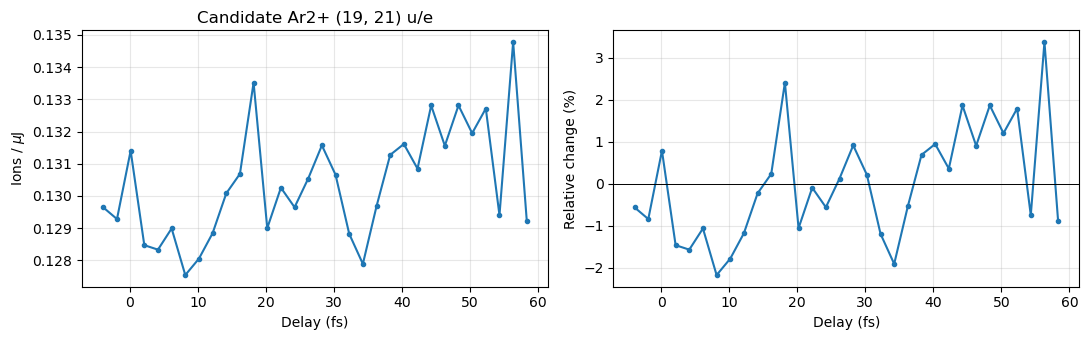

In [211]:
fig, ax = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
for j, win in enumerate([AR_PHOTO, AR_AUGER]):
    gate = in_win(ke, *win)
    for key, label in [('n', 'per shot'), ('g', 'per µJ'), ('m', 'per VLS')]:
        counts = electron_combined['e'][:, gate].sum(axis=1)
        exposure = electron_combined[key]
        y = divide(counts, exposure)
        ref = delay_reference(counts, exposure)
        y[electron_combined['n'] < MIN_SHOTS] = np.nan
        ax[0, j].plot(delay, 100*(divide(y, ref)-1), '.-', label=label)
    for i, (name, s) in enumerate(electron_scans.items()):
        counts = s['e'][:, gate].sum(axis=1)
        exposure = s[electron_exposure_key]
        y = divide(counts, exposure)
        y[s['n'] < MIN_SHOTS] = np.nan
        ax[1, j].plot(delay, 100*(divide(y, delay_reference(counts, exposure))-1), '.-', label=f'Scan {i+1}')
    ax[0, j].set_title(f'{win} eV | monitors')
    ax[1, j].set(title='Individual scans', xlabel='Delay (fs)')
for a in ax.flat:
    a.axhline(0, color='k', lw=0.7)
    a.set_ylabel('Relative change (%)')
    a.grid(alpha=0.3)
    a.legend(fontsize=8)
fig.suptitle(electron_label)
fig.tight_layout()
plt.show()

# Candidate Ar2+ ion yield: an additional single-particle reference.
ion_gate = in_win(mq, *AR_ION)
if ion_gate.any():
    counts = combined['i'][:, ion_gate].sum(axis=1)
    exposure = combined[exposure_key]
    y = divide(counts, exposure)
    y[combined['n']<MIN_SHOTS] = np.nan
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), sharex=True)
    ax[0].plot(delay, y, '.-')
    ax[1].plot(delay, 100*(divide(y, delay_reference(counts, exposure))-1), '.-')
    ax[0].set(ylabel=f'Ions / {unit}', title=f'Candidate Ar2+ {AR_ION} u/e')
    ax[1].set_ylabel('Relative change (%)')
    ax[1].axhline(0, color='k', lw=0.7)
    for a in ax:
        a.set_xlabel('Delay (fs)')
        a.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()


## Covariance preparation (shared by sections 2–8)
Read one GMD–delay cell at a time, retaining EE and EI matrices (no unused ion–ion matrix). Same population-moment convention as the source. Total pools raw moments within each delay; other estimators subtract common-mode covariance inside each acquisition/GMD/delay cell before shot-weighted pooling.

Ar is the sum of recorded bins selected by `AR_CONDITION`. Its variance must include diagonal second moments. The dead-time band is applied only afterwards. Multivariable partial covariance uses a standardised monitor covariance matrix, rejecting singular or ill-conditioned cells, not silently regularising them. With `COMMON_COV_SELECTION=True`, enabled methods share accepted cells; coverage is printed. Turning it off permits individual selections but comparisons may then reflect changed shot populations. The GMD–VLS cross-moment is optional; if unavailable the triple monitor correction is skipped explicitly. No higher moments are available for exact covariance errors.

`COV_NORMALISE_GMD` applies to ROI delay traces only; maps and intensity scaling are always raw covariance per shot. `COV_DENSITY` applies only to gated spectra. The default common selection can remove cells that the old notebook accepted; inspect the printed shot counts before comparing with old results.

In [212]:
# ---- Calibrated and rebinned covariance axes ----------------------------
def rebin_edges(edges, factor):
    return np.r_[edges[:-1:factor], edges[-1]]

def rebin_vector(x, idx):
    return np.add.reduceat(np.asarray(x, dtype=float), idx)

def rebin_matrix(x, idx1, idx2):
    x = np.add.reduceat(np.asarray(x, dtype=float), idx1, axis=0)
    return np.add.reduceat(x, idx2, axis=1)

if min(REBIN_E, REBIN_I) < 1 or any(int(v) != v for v in (REBIN_E, REBIN_I)):
    raise ValueError('Rebin factors must be positive integers')
if not COV_FILES or any(p not in FILES for p in COV_FILES):
    raise ValueError('COV_FILES must be a non-empty subset of FILES')
idx_e = np.arange(0, len(ke), REBIN_E)
idx_i = np.arange(0, len(mq), REBIN_I)
cov_ke_edges = rebin_edges(ke_edges, REBIN_E)
cov_mq_edges = rebin_edges(mq_edges, REBIN_I)
cov_ke = (cov_ke_edges[:-1] + cov_ke_edges[1:])/2
cov_mq = (cov_mq_edges[:-1] + cov_mq_edges[1:])/2
cov_dke, cov_dmq = np.diff(cov_ke_edges), np.diff(cov_mq_edges)
ne, ni, nz = len(cov_ke), len(cov_mq), len(delay)
cov_tof = calibration.tof_of_ke(cov_ke)
band = np.abs(cov_tof[:, None] - cov_tof[None, :]) <= DEAD_TIME_NS
ar_gate = in_win(cov_ke, *AR_CONDITION)
if not ar_gate.any():
    raise ValueError('Empty Ar conditioning gate')
print('Ar conditioning bin edges (eV):', cov_ke_edges[np.flatnonzero(ar_gate)[0]],
      cov_ke_edges[np.flatnonzero(ar_gate)[-1]+1])

# All ROI definitions are integrated once, and also kept per run/intensity bin.
roi_defs = {'Ar EE': ('DD', AR_PHOTO, AR_AUGER),
            'Ar EI': ('DC', AR_PHOTO, AR_ION)}
roi_defs.update({f'EE {i+1}': ('DD', *r) for i, r in enumerate(EE_ROIS)})
roi_defs.update({f'EI {i+1}': ('DC', *r) for i, r in enumerate(EI_ROIS)})
if HOLDOUT_EE is not None:
    roi_defs['Holdout EE'] = ('DD', *HOLDOUT_EE)
if HOLDOUT_EI is not None:
    roi_defs['Holdout EI'] = ('DC', *HOLDOUT_EI)
roi_masks = {}
for name, (kind, w1, w2) in roi_defs.items():
    g1 = in_win(cov_ke, *w1)
    g2 = in_win(cov_ke if kind == 'DD' else cov_mq, *w2)
    if kind == 'DD' and np.any(g1 & g2):
        raise ValueError(f'{name}: use non-overlapping EE windows')
    roi = g1[:, None] & g2[None, :]
    if kind == 'DD':
        roi &= ~band
    if not roi.any():
        print(f'{name}: empty or all pair pixels excluded; skipped')
        continue
    if name.startswith('Holdout') and (np.any(g1 & ar_gate) or (kind == 'DD' and np.any(g2 & ar_gate))):
        raise ValueError(f'{name}: overlaps Ar conditioning gate')
    roi_masks[name] = (kind, roi)
    print(f'{name}: {w1} × {w2} | retained {roi.sum()}/{g1.sum()*g2.sum()} pixels')
if 'Ar EE' not in roi_masks:
    raise ValueError('Select an accessible non-overlapping Ar photoelectron–Auger pair')

Ar conditioning bin edges (eV): 15.075572551655242 23.31667365329599
Ar EE: (14.800000000000011, 22.80000000000001) × (200, 208) | retained 72/72 pixels
Ar EI: (14.800000000000011, 22.80000000000001) × (19, 21) | retained 45/45 pixels
EE 1: (242, 246) × (180, 200) | retained 80/80 pixels
EE 2: (242, 246) × (200, 210) | retained 39/40 pixels
EE 3: (246, 249) × (210, 220) | retained 10/30 pixels
EE 4: empty or all pair pixels excluded; skipped
EE 5: (246, 249) × (180, 200) | retained 60/60 pixels
EE 6: (246, 249) × (200, 210) | retained 30/30 pixels
EE 7: (250, 260) × (180, 200) | retained 200/200 pixels
EI 1: (220, 240) × (0.5, 1.5) | retained 260/260 pixels
EI 2: (220, 240) × (12, 16) | retained 260/260 pixels
EI 3: (220, 240) × (19, 21) | retained 100/100 pixels
EI 4: (220, 240) × (27, 32) | retained 220/220 pixels
EI 5: (220, 240) × (43, 45) | retained 80/80 pixels


In [213]:
# ---- Check which monitor moments are available --------------------------
base_keys = ['n_per_bin', 'D', 'C', 'G', 'DtD', 'DtC', 'DtG', 'CtG', 'GtG']
vls_keys = ['A', 'AtA', 'AtD', 'AtC']
triple_available = RUN_VLS_COV and RUN_AR_COV and RUN_MULTI_COV
for path in COV_FILES:
    with h5py.File(path, 'r') as f:
        required = base_keys + (vls_keys if RUN_VLS_COV else [])
        missing = [key for key in required if key not in f]
        if missing:
            raise KeyError(f'{path.name}: missing {missing}')
        nshape = f['n_per_bin'].shape
        expected = {'D': (*nshape, len(ke)), 'C': (*nshape, len(mq)), 'G': nshape,
                    'DtD': (*nshape, len(ke), len(ke)), 'DtC': (*nshape, len(ke), len(mq)),
                    'DtG': (*nshape, len(ke)), 'CtG': (*nshape, len(mq)), 'GtG': nshape}
        if RUN_VLS_COV:
            nv = f['A'].shape[-1]
            expected.update(A=(*nshape, nv), AtA=(*nshape, nv, nv),
                            AtD=(*nshape, nv, len(ke)), AtC=(*nshape, nv, len(mq)))
            if GMD_VLS_MOMENT not in f or f[GMD_VLS_MOMENT].shape not in ((*nshape, nv), nshape, (*nshape, 1)):
                triple_available = False
                print(f'{path.name}: GMD–VLS cross-moment unavailable / unsupported shape')
        for key, shape in expected.items():
            if f[key].shape != shape:
                raise ValueError(f'{path.name}: {key} {f[key].shape} != {shape}')

methods = {'total': (), 'within GMD bins': (), 'partial on GMD': ('GMD',)}
if RUN_VLS_COV:
    methods['partial on VLS'] = ('VLS',)
if RUN_AR_COV:
    methods['partial on Ar'] = ('Ar',)
if RUN_MULTI_COV:
    if RUN_AR_COV:
        methods['partial on GMD + Ar'] = ('GMD', 'Ar')
    if RUN_AR_COV and RUN_VLS_COV:
        methods['partial on VLS + Ar'] = ('VLS', 'Ar')
    if triple_available:
        methods['partial on GMD + VLS + Ar'] = ('GMD', 'VLS', 'Ar')
    else:
        print('Triple correction disabled: requires a verified GMD–VLS moment in every file.')
if WINDOW_EST not in methods:
    raise ValueError(f'WINDOW_EST not available: {list(methods)}')
print('Methods:', list(methods))

# A small helper shared by the mixture and the optional pure-Ar template.
def cell_moments(f, idx, use_vls, use_ar, use_triple=False):
    D = rebin_vector(f['D'][idx][::-1], idx_e)
    C = rebin_vector(f['C'][idx], idx_i)
    DD = rebin_matrix(f['DtD'][idx][::-1, ::-1], idx_e, idx_e)
    DC = rebin_matrix(f['DtC'][idx][::-1, :], idx_e, idx_i)
    G = float(f['G'][idx])
    vG = float(f['GtG'][idx]) - G**2
    cDD = DD - np.outer(D, D)
    cDC = DC - np.outer(D, C)
    DG = rebin_vector(f['DtG'][idx][::-1], idx_e) - D*G
    CG = rebin_vector(f['CtG'][idx], idx_i) - C*G
    xz, yz = {'GMD': DG}, {'GMD': CG}
    zz = {('GMD', 'GMD'): vG}
    M = float(np.sum(f['A'][idx], dtype=float))/1e4 if 'A' in f else np.nan
    if use_vls:
        vM = float(np.sum(f['AtA'][idx], dtype=float))/1e8 - M**2
        DM = rebin_vector(np.sum(f['AtD'][idx], axis=0, dtype=float)[::-1], idx_e)/1e4 - D*M
        CM = rebin_vector(np.sum(f['AtC'][idx], axis=0, dtype=float), idx_i)/1e4 - C*M
        xz['VLS'], yz['VLS'] = DM, CM
        zz['VLS', 'VLS'] = vM
        if use_triple:
            GM = float(np.sum(f[GMD_VLS_MOMENT][idx], dtype=float))/1e4 - G*M
            zz['GMD', 'VLS'] = zz['VLS', 'GMD'] = GM
    if use_ar:
        # Full covariance, including diagonal: Var(sum of Ar counts).
        DA = cDD[:, ar_gate].sum(axis=1)
        CA = cDC[ar_gate, :].sum(axis=0)
        xz['Ar'], yz['Ar'] = DA, CA
        zz['Ar', 'Ar'] = DA[ar_gate].sum()
        zz['GMD', 'Ar'] = zz['Ar', 'GMD'] = DG[ar_gate].sum()
        if use_vls:
            zz['VLS', 'Ar'] = zz['Ar', 'VLS'] = DM[ar_gate].sum()
    if not all(np.isfinite(v).all() for v in (D, C, DD, DC, DG, CG)):
        raise ValueError(f'{f.filename}: non-finite populated moment at {idx}')
    return D, C, DD, DC, cDD, cDC, G, M, xz, yz, zz


def partial_pair(cDD, cDC, xz, yz, zz, monitors):
    # Standardise monitors before testing conditioning / solving.
    if not monitors:
        return cDD, cDC
    Z = np.array([[zz[a, b] for b in monitors] for a in monitors])
    if not np.isfinite(Z).all() or np.any(np.diag(Z) <= 0):
        return None
    sd = np.sqrt(np.diag(Z))
    R = Z / np.outer(sd, sd)
    if np.linalg.eigvalsh(R)[0] <= 0 or np.linalg.cond(R) > MONITOR_COND_MAX:
        return None
    X = np.column_stack([xz[a] for a in monitors]) / sd
    Y = np.column_stack([yz[a] for a in monitors]) / sd
    if not np.isfinite(X).all() or not np.isfinite(Y).all():
        return None
    W = np.linalg.solve(R, X.T).T
    pDD = cDD - W @ X.T
    return (pDD + pDD.T)/2, cDC - W @ Y.T

Methods: ['total', 'within GMD bins', 'partial on GMD', 'partial on VLS', 'partial on Ar', 'partial on GMD + Ar', 'partial on VLS + Ar', 'partial on GMD + VLS + Ar']


Time-resolved matrix storage: 212.6 MB (plus temporary cell arrays)


AcH_long_delay_scan_1_269.7eV_2810289120_aggregates_tr.h5 | eligible: 2,459,088 | accepted: {'total': 2459088, 'within GMD bins': 2459088, 'partial on GMD': 2459088, 'partial on VLS': 2459088, 'partial on Ar': 2459088, 'partial on GMD + Ar': 2459088, 'partial on VLS + Ar': 2459088, 'partial on GMD + VLS + Ar': 2459088}
AcH_long_delay_scan_2_269.7eV_2810315452_aggregates_tr.h5 | eligible: 2,457,818 | accepted: {'total': 2457818, 'within GMD bins': 2457818, 'partial on GMD': 2457818, 'partial on VLS': 2457818, 'partial on Ar': 2457818, 'partial on GMD + Ar': 2457818, 'partial on VLS + Ar': 2457818, 'partial on GMD + VLS + Ar': 2457818}
AcH_long_delay_scan_3_269.7eV_2810342023_aggregates_tr.h5 | eligible: 2,453,743 | accepted: {'total': 2453743, 'within GMD bins': 2453743, 'partial on GMD': 2453743, 'partial on VLS': 2453743, 'partial on Ar': 2453743, 'partial on GMD + Ar': 2453743, 'partial on VLS + Ar': 2453743, 'partial on GMD + VLS + Ar': 2453743}
Shots rejected by individual monitor 

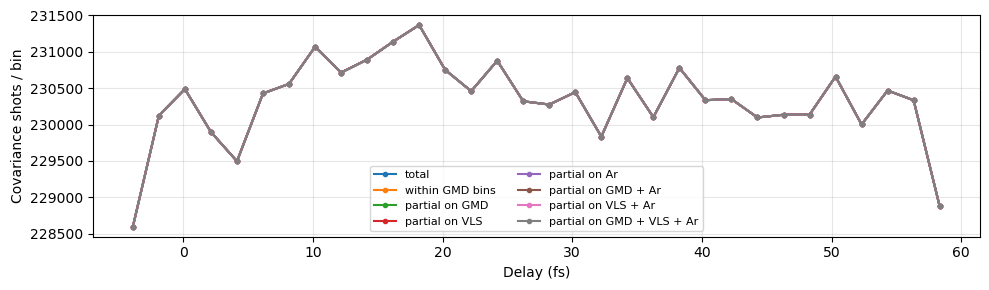

In [214]:
# ---- Calculate time-resolved covariance in a single pass ----------------
size_mb = len(methods)*nz*(ne*ne + ne*ni)*8/1e6
print(f'Time-resolved matrix storage: {size_mb:.1f} MB (plus temporary cell arrays)')
if size_mb > MAX_MATRIX_MB:
    raise MemoryError('Increase rebinning, select shorter scans, or disable optional methods')
EST = {name: {'DD': np.zeros((nz, ne, ne)), 'DC': np.zeros((nz, ne, ni))} for name in methods}
n_by = {name: np.zeros(nz) for name in methods}
g_by = {name: np.zeros(nz) for name in methods}
m_by = {name: np.zeros(nz) for name in methods}
D_sum, C_sum = np.zeros((nz, ne)), np.zeros((nz, ni))
rejected = {name: 0 for name in methods}
cell_records = []     # integrated ROI values per GMD-delay cell (small)
run_stats = {}
monitor_records = []

for path in COV_FILES:
    used = {name: 0 for name in methods}
    eligible = 0
    with h5py.File(path, 'r') as f:
        for key in axes:
            np.testing.assert_array_equal(f[key][:], axes[key])
        n = f['n_per_bin'][:]
        bins = np.arange(n.shape[0]) if COV_GMD_BINS is None else np.arange(n.shape[0])[COV_GMD_BINS]
        if len(np.unique(bins)) != len(bins):
            raise ValueError('Duplicate GMD bin indices')
        for j in bins:
            for k in range(nz):
                N = int(n[j, k])
                if N < MIN_COV_SHOTS:
                    continue
                # Source notebook excludes invalid GMD variance for all methods.
                G0 = float(f['G'][j, k])
                vG = float(f['GtG'][j, k]) - G0**2
                if not np.isfinite(vG) or vG <= 0:
                    continue
                eligible += N
                iz = k if DELAY_SIGN == 1 else nz-1-k
                D, C, DD, DC, cDD, cDC, G, M, xz, yz, zz = cell_moments(
                    f, (j, k), RUN_VLS_COV, RUN_AR_COV, triple_available)
                estimates = {'total': (DD, DC), 'within GMD bins': (cDD, cDC)}
                for name, monitors in methods.items():
                    if monitors:
                        estimates[name] = partial_pair(cDD, cDC, xz, yz, zz, monitors)
                        if estimates[name] is None:
                            rejected[name] += N
                if COMMON_COV_SELECTION and any(v is None for v in estimates.values()):
                    continue
                if RUN_AR_COV:
                    rec = dict(run=path.name, iz=iz, gmd_bin=int(j), n=N, gmd=G, ar=D[ar_gate].sum())
                    for monitor in ('GMD', 'VLS'):
                        if (monitor, 'Ar') in zz and zz[monitor, monitor]>0 and zz['Ar','Ar']>0:
                            rec[monitor] = zz[monitor, 'Ar']/np.sqrt(zz[monitor,monitor]*zz['Ar','Ar'])
                        else:
                            rec[monitor] = np.nan
                    monitor_records.append(rec)
                D_sum[iz] += N*D
                C_sum[iz] += N*C
                for name, result in estimates.items():
                    if result is None:
                        continue
                    pDD, pDC = result
                    EST[name]['DD'][iz] += N*pDD
                    EST[name]['DC'][iz] += N*pDC
                    n_by[name][iz] += N
                    g_by[name][iz] += N*G
                    m_by[name][iz] += N*M
                    used[name] += N
                    if name == 'total':
                        continue  # pooled total cannot be reconstructed by averaging cell covariances
                    rec = dict(run=path.name, gmd_bin=int(j), iz=iz, n=N, gmd=G, vls=M, method=name)
                    for label, (kind, mask) in roi_masks.items():
                        rec[label] = (pDD if kind == 'DD' else pDC)[mask].sum()
                    cell_records.append(rec)
    run_stats[path.name] = used
    print(path.name, '| eligible:', f'{eligible:,}', '| accepted:', used)

for name, E in EST.items():
    for key in ('DD', 'DC'):
        np.divide(E[key], n_by[name][:, None, None], out=E[key], where=n_by[name][:, None, None]>0)
        E[key][n_by[name]==0] = np.nan
mD = divide(D_sum, n_by['total'][:, None])
mC = divide(C_sum, n_by['total'][:, None])
for k in range(nz):
    EST['total']['DD'][k] -= np.outer(mD[k], mD[k])
    EST['total']['DC'][k] -= np.outer(mD[k], mC[k])
print('Shots rejected by individual monitor validity tests:', rejected)
for name in methods:
    print(f'{name}: {n_by[name].sum():,.0f} shots')
if COMMON_COV_SELECTION:
    for n in n_by.values():
        np.testing.assert_array_equal(n, n_by['total'])
if not n_by[WINDOW_EST].any():
    raise ValueError('No valid covariance cells. Inspect monitor validity or disable optional corrections.')

cov_delay_mask = np.ones(nz, dtype=bool) if COV_DELAY_WINDOW is None else in_win(delay, *COV_DELAY_WINDOW)
EST_AV = {}
for name, E in EST.items():
    use = cov_delay_mask & (n_by[name]>0)
    if use.any():
        w = n_by[name][use]/n_by[name][use].sum()
        EST_AV[name] = {key: np.tensordot(w, M[use], axes=1) for key, M in E.items()}

if WINDOW_EST not in EST_AV:
    raise ValueError('No accepted covariance shots in COV_DELAY_WINDOW')

fig, ax = plt.subplots(figsize=(10, 3))
for name, n in n_by.items():
    ax.plot(delay, n, '.-', label=name)
ax.set(xlabel='Delay (fs)', ylabel='Covariance shots / bin')
ax.legend(fontsize=8, ncol=2)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

In [215]:
# ---- Shared plot and integration helpers --------------------------------
def show_cov_map(ax, M, x_edges, y_edges, vmax=None, label='Covariance'):
    if vmax is None or not np.isfinite(vmax) or vmax <= 0:
        finite = np.abs(M[np.isfinite(M)])
        vmax = np.percentile(finite, CLIP_PCT) if finite.size else 1
        vmax = vmax if vmax > 0 else 1
    im = ax.pcolormesh(x_edges, y_edges, M, cmap='RdBu_r', shading='flat',
                       vmin=-vmax, vmax=vmax)
    plt.colorbar(im, ax=ax, label=label, fraction=0.046, pad=0.02)
    return im


def roi_trace(method, label, normalise=COV_NORMALISE_GMD):
    kind, mask = roi_masks[label]
    y = EST[method][kind][:, mask].sum(axis=1)
    if normalise:
        y = divide(y, divide(g_by[method], n_by[method]))
    return y


def reference(y, n):
    good = ref_mask & np.isfinite(y) & (n>0)
    return np.average(y[good], weights=n[good]) if good.any() else np.nan


def relative(y, n):
    # Signed covariance: use |baseline|, never divide by a zero baseline.
    ref = reference(y, n)
    if not np.isfinite(ref) or ref == 0:
        return np.full_like(y, np.nan, dtype=float)
    return 100*(y-ref)/abs(ref)


def ee_gated(M, gate):
    valid = gate[:, None] & ~band
    result = np.sum(np.where(valid, M, 0), axis=-2)
    result[..., ~valid.any(axis=0)] = np.nan
    return result

base_methods = [m for m in ('total', 'within GMD bins', 'partial on GMD', 'partial on VLS') if m in EST_AV]
cov_label = 'Covariance / GMD' if COV_NORMALISE_GMD else 'Covariance per shot'

## 2. Argon–argon covariance reference
Inspect the full EE/EI maps, then zoom on candidate argon islands. Both Ar EE and Ar EI are possible reference observables; EI can contain molecular fragments at similar mass. Compare the same covariance estimator and the same selected shots. The molecular gates are inherited from the AcH notebook.

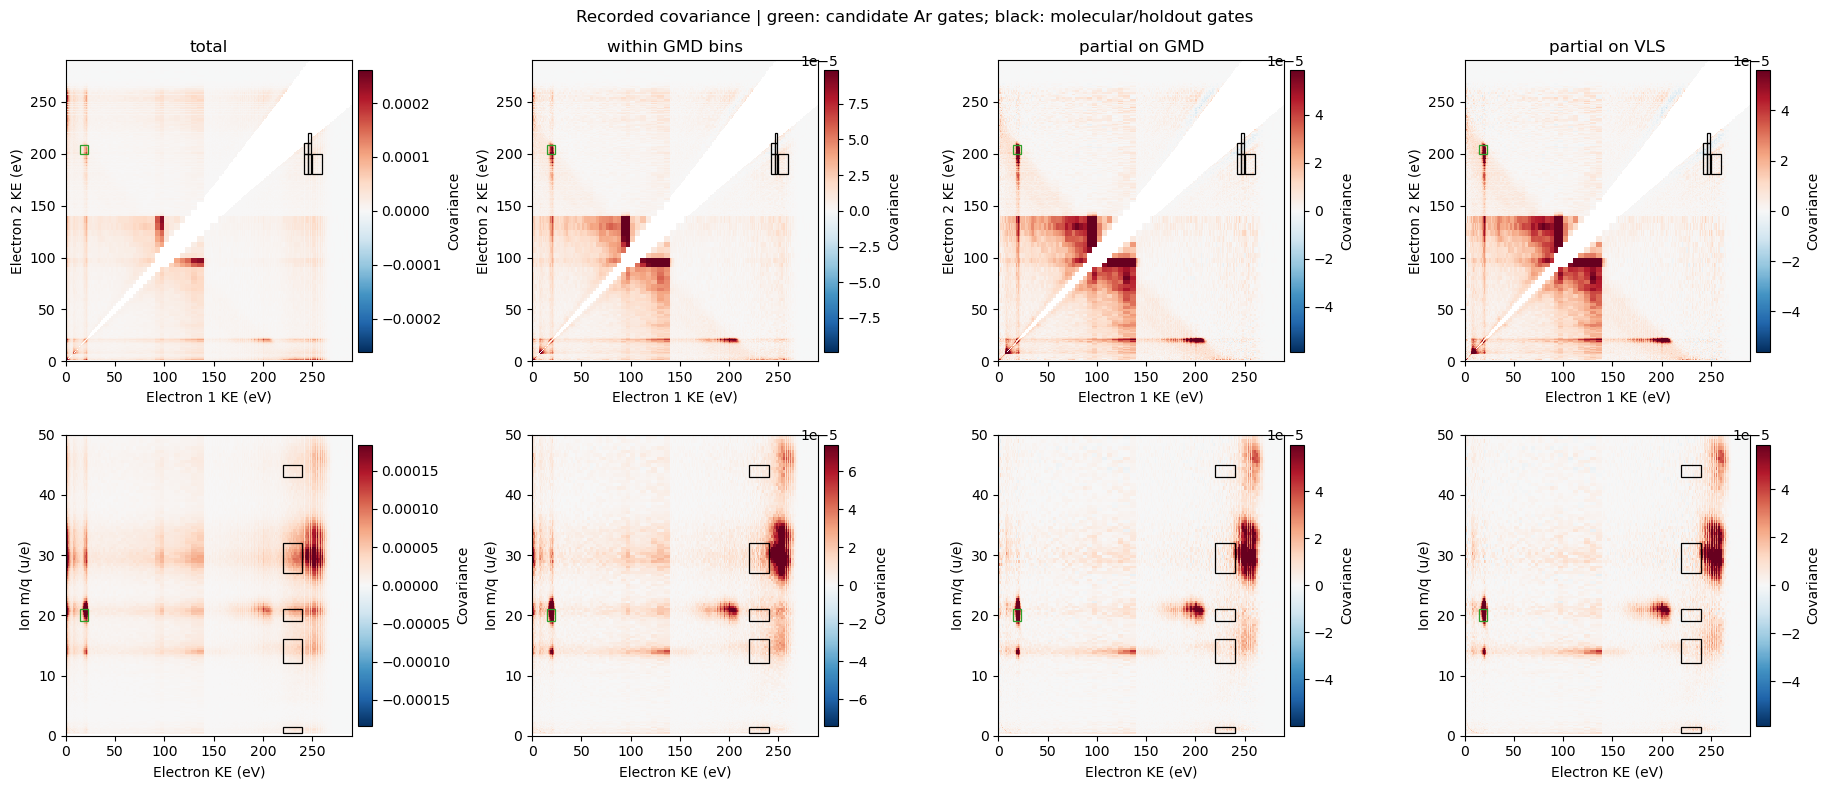

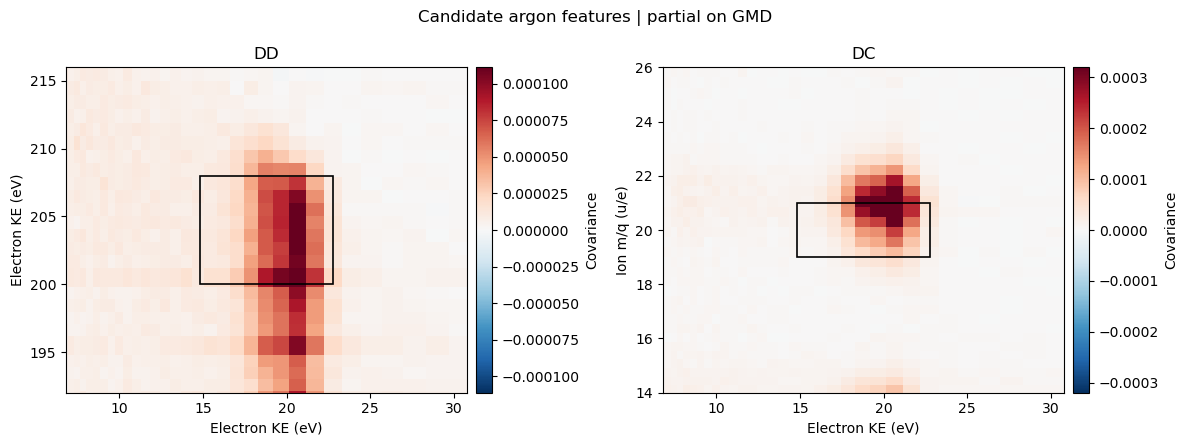

In [216]:
# Full maps, with independent colour scales for EE and EI.
fig, ax = plt.subplots(2, len(base_methods), figsize=(4.6*len(base_methods), 8), squeeze=False)
for j, name in enumerate(base_methods):
    E = EST_AV[name]
    show_cov_map(ax[0, j], np.where(band, np.nan, E['DD']).T,
                 cov_ke_edges, cov_ke_edges)
    show_cov_map(ax[1, j], E['DC'].T, cov_ke_edges, cov_mq_edges)
    ax[0, j].set(title=name, xlabel='Electron 1 KE (eV)', ylabel='Electron 2 KE (eV)',
                 xlim=COV_KE_LIM, ylim=COV_KE_LIM)
    ax[1, j].set(xlabel='Electron KE (eV)', ylabel='Ion m/q (u/e)',
                 xlim=COV_KE_LIM, ylim=COV_MQ_LIM)
    for label, (kind, w1, w2) in roi_defs.items():
        if label not in roi_masks:
            continue
        a = ax[0 if kind=='DD' else 1, j]
        color = 'C2' if label.startswith('Ar') else 'k'
        a.add_patch(Rectangle((w1[0], w2[0]), w1[1]-w1[0], w2[1]-w2[0],
                              fill=False, lw=0.9, edgecolor=color))
fig.suptitle('Recorded covariance | green: candidate Ar gates; black: molecular/holdout gates')
fig.tight_layout()
plt.show()

E = EST_AV[WINDOW_EST]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, kind, win, edges, centres in [(ax[0], 'DD', AR_AUGER, cov_ke_edges, cov_ke),
                                     (ax[1], 'DC', AR_ION, cov_mq_edges, cov_mq)]:
    M = np.where(band, np.nan, E[kind]) if kind=='DD' else E[kind]
    xlim = (max(0, AR_PHOTO[0]-8), AR_PHOTO[1]+8)
    ylim = (win[0]-8, win[1]+8) if kind=='DD' else (max(0, win[0]-5), win[1]+5)
    local = M[np.ix_(in_win(cov_ke,*xlim), in_win(centres,*ylim))]
    vals = np.abs(local[np.isfinite(local)])
    vmax = np.percentile(vals, CLIP_PCT) if vals.size else None
    show_cov_map(a, M.T, cov_ke_edges, edges, vmax=vmax)
    a.add_patch(Rectangle((AR_PHOTO[0], win[0]), AR_PHOTO[1]-AR_PHOTO[0], win[1]-win[0],
                          fill=False, edgecolor='k', lw=1.2))
    a.set(xlim=xlim, ylim=ylim, xlabel='Electron KE (eV)',
          ylabel='Electron KE (eV)' if kind=='DD' else 'Ion m/q (u/e)', title=kind)
fig.suptitle(f'Candidate argon features | {WINDOW_EST}')
fig.tight_layout()
plt.show()

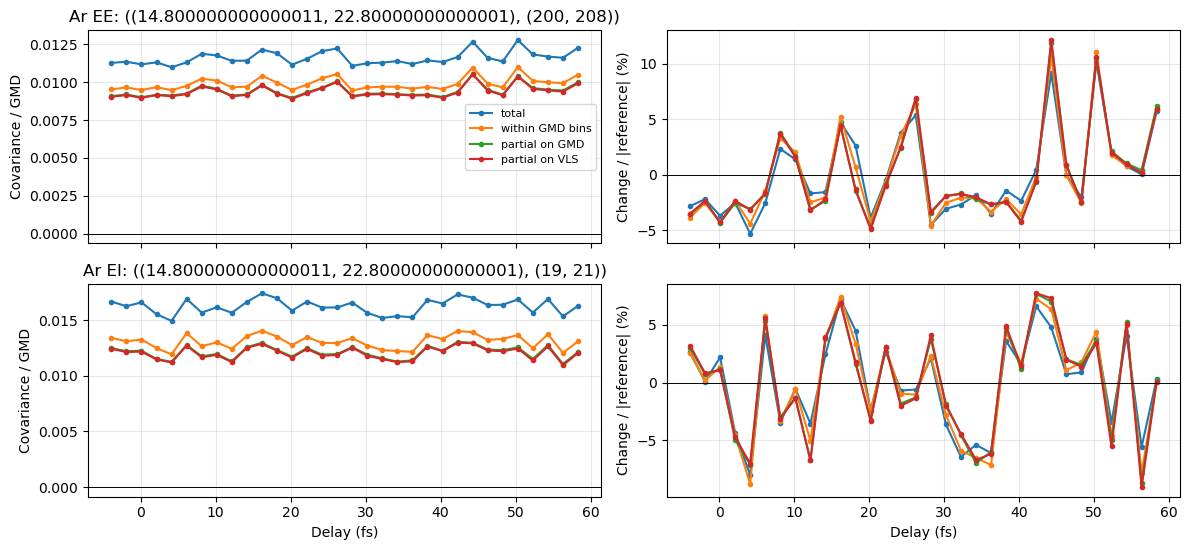

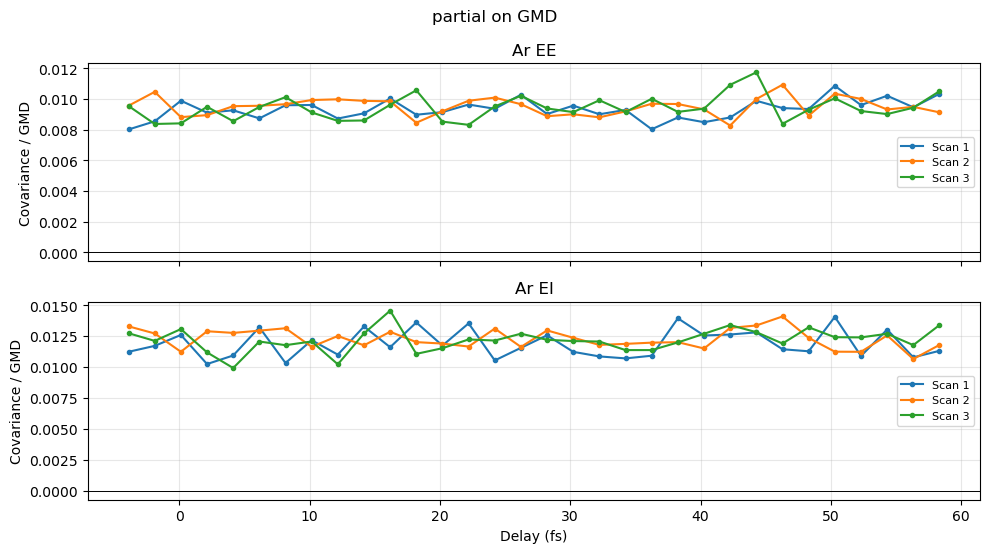

In [217]:
labels = [l for l in roi_masks if l.startswith(('Ar', 'Holdout'))]
fig, ax = plt.subplots(len(labels), 2, figsize=(12, 2.8*len(labels)), sharex=True, squeeze=False)
for j, label in enumerate(labels):
    for method in base_methods:
        y = roi_trace(method, label)
        ax[j, 0].plot(delay, y, '.-', label=method)
        ax[j, 1].plot(delay, relative(y, n_by[method]), '.-', label=method)
    ax[j, 0].set(title=f'{label}: {roi_defs[label][1:]}', ylabel=cov_label)
    ax[j, 1].set_ylabel('Change / |reference| (%)')
for a in ax.flat:
    a.axhline(0, color='k', lw=0.7)
    a.grid(alpha=0.3)
for a in ax[-1]:
    a.set_xlabel('Delay (fs)')
ax[0, 0].legend(fontsize=8)
fig.tight_layout()
plt.show()

# Independent acquisition check (cell-wise estimators only).
# 'total' cannot be reconstructed from these per-cell covariance scalars.
run_method = WINDOW_EST if WINDOW_EST in base_methods and WINDOW_EST != 'total' else 'within GMD bins'
fig, ax = plt.subplots(len(labels), 1, figsize=(10, 2.8*len(labels)), sharex=True, squeeze=False)
for j, label in enumerate(labels):
    for i, path in enumerate(COV_FILES):
        rr = [r for r in cell_records if r['run']==path.name and r['method']==run_method]
        s, n, g = np.zeros(nz), np.zeros(nz), np.zeros(nz)
        for r in rr:
            k = r['iz']; s[k] += r['n']*r[label]; n[k] += r['n']; g[k] += r['n']*r['gmd']
        y = divide(s, g if COV_NORMALISE_GMD else n)
        ax[j, 0].plot(delay, y, '.-', label=f'Scan {i+1}')
    ax[j, 0].set(title=label, ylabel=cov_label)
    ax[j, 0].axhline(0, color='k', lw=0.7)
    ax[j, 0].grid(alpha=0.3)
    ax[j, 0].legend(fontsize=8)
ax[-1, 0].set_xlabel('Delay (fs)')
fig.suptitle(run_method)
fig.tight_layout()
plt.show()

## 3. Molecular covariance / argon covariance
First check intensity scaling within each run, using the selected GMD bins and delay interval. The slope is descriptive (covariance versus **mean** intensity within a bin), not a photon-order measurement. In particular, a two-pulse response depends on the pump–probe intensity product, not just total intensity. A ratio can remove common multiplicative drift only if the channels share the appropriate scaling.

The ratio uses raw per-shot covariance, independent of `COV_NORMALISE_GMD`. Its dimensionless form is `(molecular covariance / |molecular baseline|) / (argon covariance / argon baseline)**RATIO_POWER`; subtract its baseline for display. Negative or weak reference bins are masked. Use the EE Ar reference for EE and EI Ar reference for EI; if either is not usable the corresponding ratio is skipped. No uncertainty reduction is assumed.

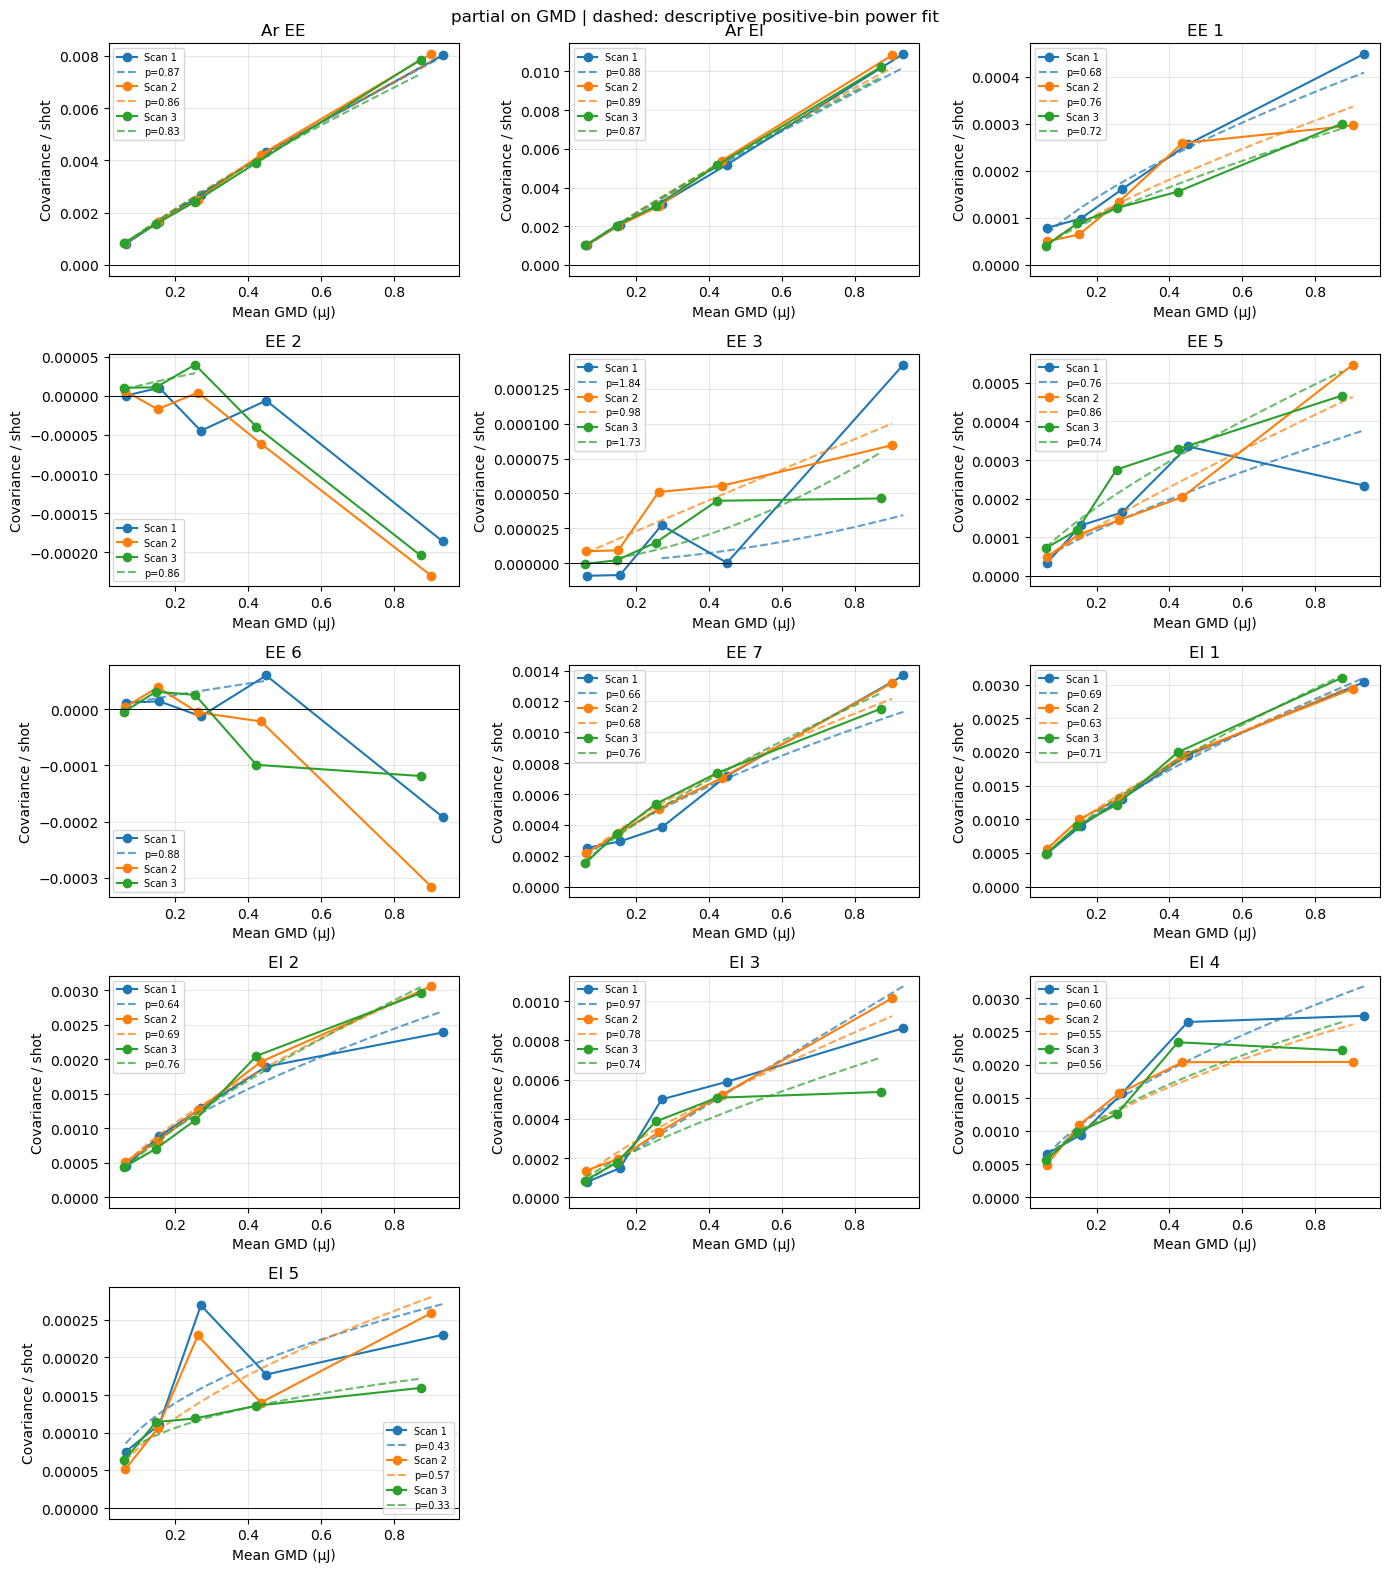

In [192]:
# ---- Intensity dependence (within each acquisition) ---------------------
int_method = WINDOW_EST if WINDOW_EST != 'total' else 'within GMD bins'
if INTENSITY_MONITOR not in ('gmd', 'vls'):
    raise ValueError('INTENSITY_MONITOR must be gmd or vls')
int_labels = [l for l in roi_masks if l.startswith(('Ar', 'EE', 'EI'))]
fig, ax = plt.subplots(int(np.ceil(len(int_labels)/3)), 3,
                       figsize=(14, 3.2*np.ceil(len(int_labels)/3)), squeeze=False)
for a, label in zip(ax.flat, int_labels):
    for i, path in enumerate(COV_FILES):
        rr = [r for r in cell_records if r['run']==path.name and r['method']==int_method
              and cov_delay_mask[r['iz']]]
        xx, yy = [], []
        for j in sorted({r['gmd_bin'] for r in rr}):
            group = [r for r in rr if r['gmd_bin']==j]
            w = np.array([r['n'] for r in group])
            xx.append(np.average([r[INTENSITY_MONITOR] for r in group], weights=w))
            yy.append(np.average([r[label] for r in group], weights=w))
        x, y = np.asarray(xx), np.asarray(yy)
        a.plot(x, y, 'o-', color=f'C{i%10}', label=f'Scan {i+1}')
        good = np.isfinite(x) & np.isfinite(y) & (x>0) & (y>0)
        if good.sum() >= 3 and np.ptp(x[good])>0:
            p, b = np.polyfit(np.log(x[good]), np.log(y[good]), 1)
            xf = np.geomspace(x[good].min(), x[good].max(), 50)
            a.plot(xf, np.exp(b)*xf**p, '--', color=f'C{i%10}', alpha=0.7,
                   label=f'p={p:.2f}')
    a.set(title=label, xlabel='Mean GMD (µJ)' if INTENSITY_MONITOR=='gmd' else 'Mean VLS (10⁴ ADU)',
          ylabel='Covariance / shot')
    a.axhline(0, color='k', lw=0.7)
    a.legend(fontsize=7)
    a.grid(alpha=0.3)
for a in list(ax.flat)[len(int_labels):]:
    a.set_visible(False)
fig.suptitle(f'{int_method} | dashed: descriptive positive-bin power fit')
fig.tight_layout()
plt.show()

EE 1: 32/32 usable denominator bins; Ar baseline=0.00342
EE 2: 32/32 usable denominator bins; Ar baseline=0.00342
EE 3: 32/32 usable denominator bins; Ar baseline=0.00342
EE 5: 32/32 usable denominator bins; Ar baseline=0.00342
EE 6: 32/32 usable denominator bins; Ar baseline=0.00342
EE 7: 32/32 usable denominator bins; Ar baseline=0.00342
EI 1: 32/32 usable denominator bins; Ar baseline=0.00441
EI 2: 32/32 usable denominator bins; Ar baseline=0.00441
EI 3: 32/32 usable denominator bins; Ar baseline=0.00441
EI 4: 32/32 usable denominator bins; Ar baseline=0.00441
EI 5: 32/32 usable denominator bins; Ar baseline=0.00441


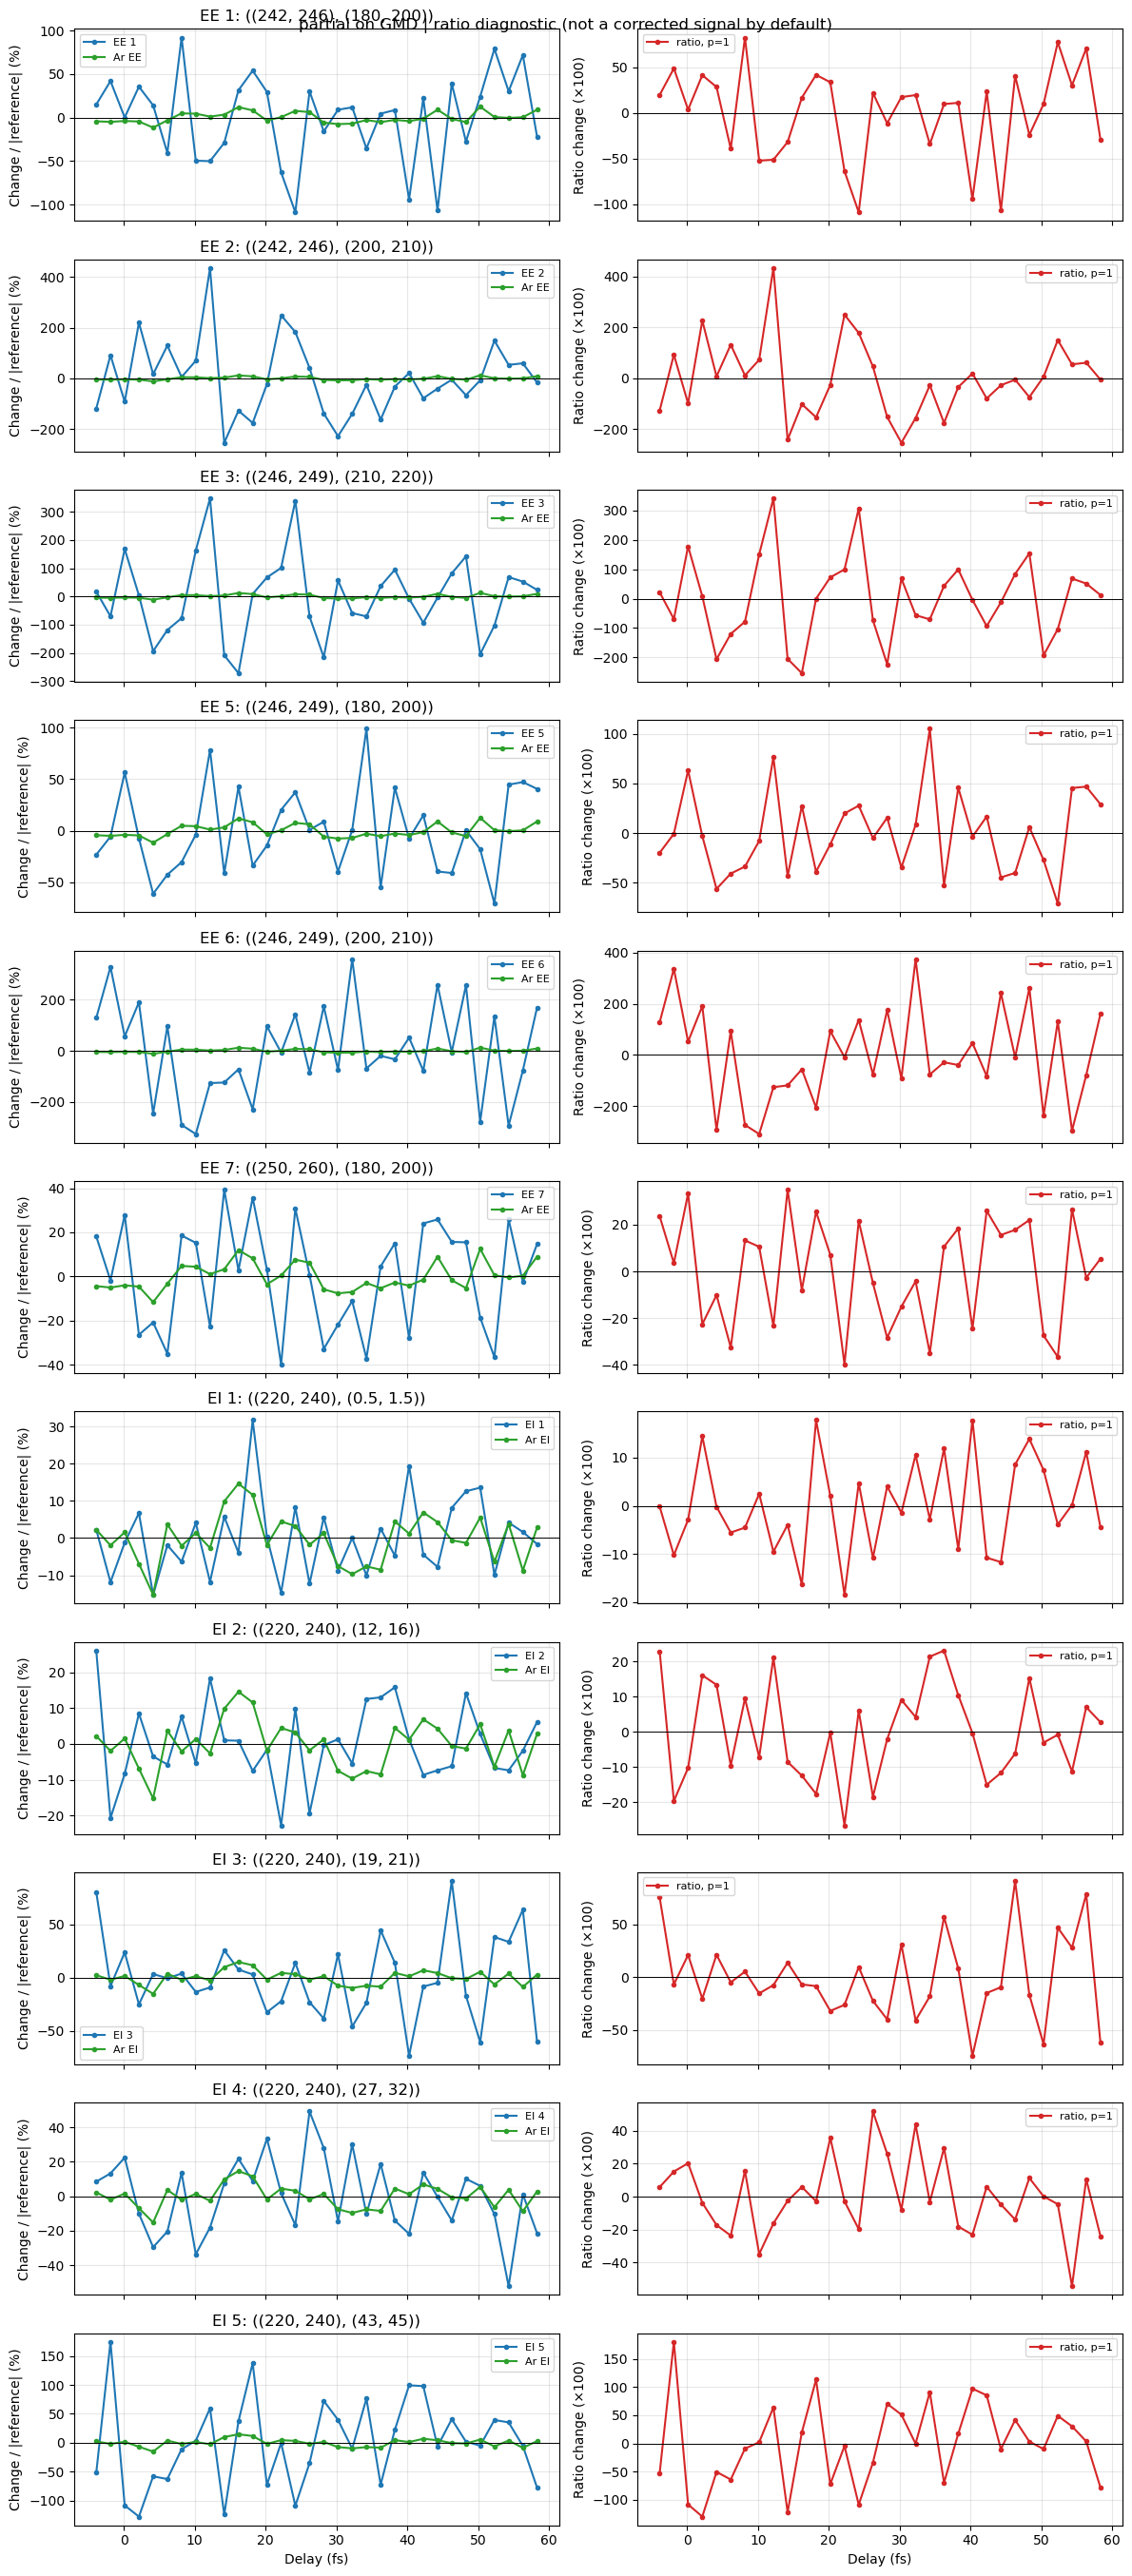

In [193]:
# ---- Ratios, without changing the original covariance -------------------
if 'Ar' in methods[WINDOW_EST]:
    print('Choose an estimator NOT conditioned on Ar for the ratio (e.g. partial on GMD).')
else:
    mol_labels = [l for l in roi_masks if l.startswith(('EE ', 'EI '))]
    fig, ax = plt.subplots(len(mol_labels), 2, figsize=(12, 2.5*len(mol_labels)),
                           sharex=True, squeeze=False)
    ratio_traces = {}
    n = n_by[WINDOW_EST]
    for j, label in enumerate(mol_labels):
        ref_label = 'Ar EE' if label.startswith('EE') else 'Ar EI'
        y = roi_trace(WINDOW_EST, label, normalise=False)
        ax[j, 0].plot(delay, relative(y, n), 'C0.-', label=label)
        if ref_label in roi_masks:
            ar = roi_trace(WINDOW_EST, ref_label, normalise=False)
            ar0, y0 = reference(ar, n), reference(y, n)
            ax[j, 0].plot(delay, relative(ar, n), 'C2.-', label=ref_label)
            good = np.isfinite(ar) & (ar>0) & (ar>=RATIO_MIN_FRACTION*ar0)
            if np.isfinite(ar0) and ar0>0 and np.isfinite(y0) and y0!=0:
                r = np.full(nz, np.nan)
                r[good] = (y[good]/abs(y0))/(ar[good]/ar0)**RATIO_POWER
                r0 = reference(r, n)
                ratio_traces[label] = r
                ax[j, 1].plot(delay, 100*(r-r0), 'C3.-', label=f'ratio, p={RATIO_POWER:g}')
                print(f'{label}: {good.sum()}/{nz} usable denominator bins; Ar baseline={ar0:.3g}')
            else:
                print(f'{label}: invalid/zero baseline; ratio skipped')
        ax[j, 0].set(title=f'{label}: {roi_defs[label][1:]}', ylabel='Change / |reference| (%)')
        ax[j, 1].set_ylabel('Ratio change (×100)')
    for a in ax.flat:
        a.axhline(0, color='k', lw=0.7)
        a.grid(alpha=0.3)
        if a.lines and a.get_legend_handles_labels()[0]:
            a.legend(fontsize=8)
    for a in ax[-1]:
        a.set_xlabel('Delay (fs)')
    fig.suptitle(f'{WINDOW_EST} | ratio diagnostic (not a corrected signal by default)')
    fig.tight_layout()
    plt.show()

## 4. Argon–molecule cross-covariance
Gate on the Ar photoelectron and inspect the electrons and ions covarying with it. The expected Ar photo–Auger covariance is physical. A residual outside known Ar channels can indicate additional Ar pathways, overlap, common-mode fluctuations or detector effects; it is not proof of contamination. Compare the original four estimators, without conditioning on the same Ar gate. Gated spectra are integrated over the first axis and optionally divided by the remaining bin width.

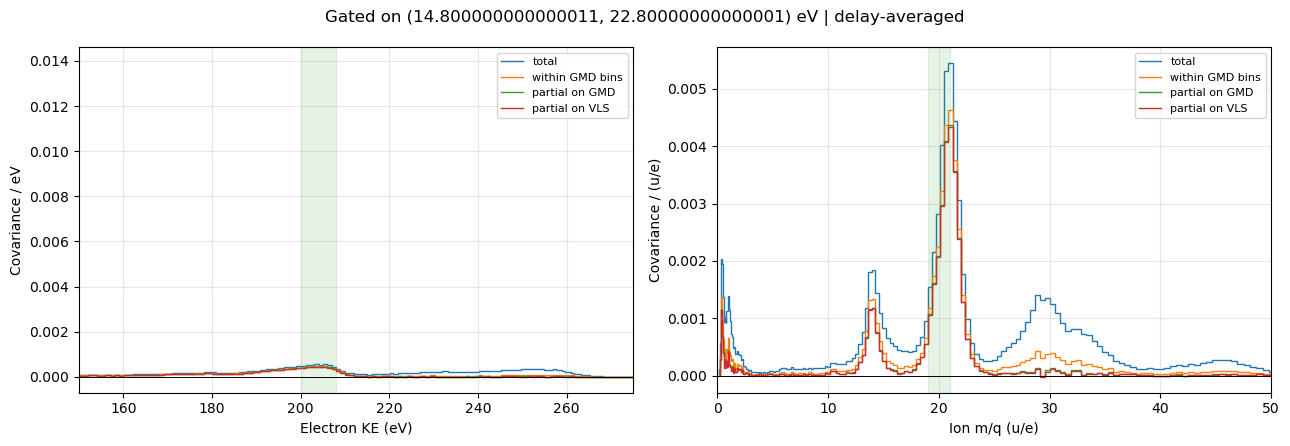

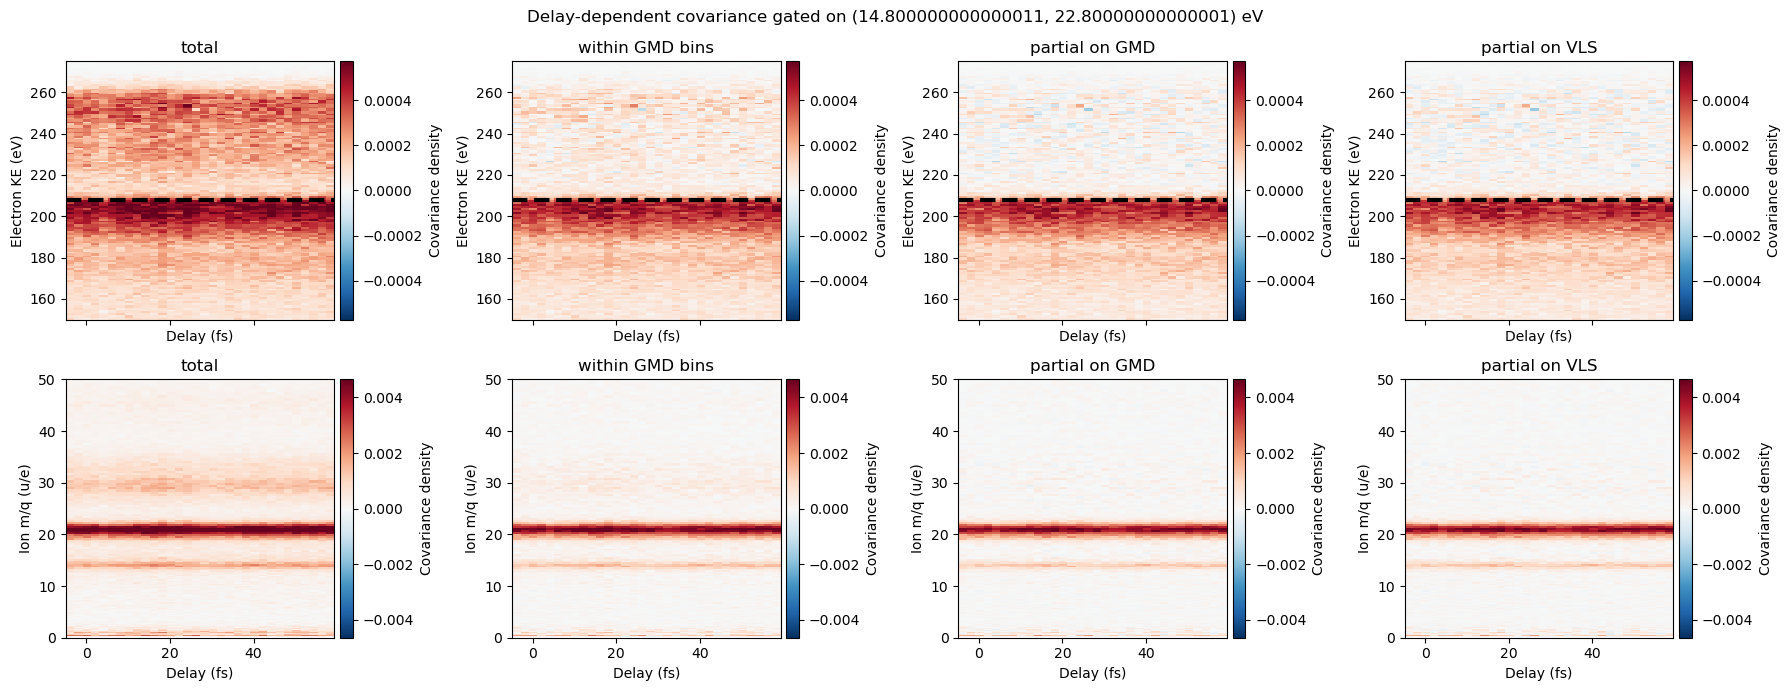

In [218]:
gate = in_win(cov_ke, *AR_PHOTO)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for name in base_methods:
    E = EST_AV[name]
    ee = ee_gated(E['DD'], gate)
    ei = E['DC'][gate, :].sum(axis=0)
    ax[0].stairs(ee/cov_dke if COV_DENSITY else ee, cov_ke_edges, label=name)
    ax[1].stairs(ei/cov_dmq if COV_DENSITY else ei, cov_mq_edges, label=name)
ax[0].axvspan(*AR_AUGER, color='C2', alpha=0.12)
ax[1].axvspan(*AR_ION, color='C2', alpha=0.12)
ax[0].set(xlabel='Electron KE (eV)', xlim=CROSS_KE_LIM,
          ylabel='Covariance / eV' if COV_DENSITY else 'Covariance / bin')
ax[1].set(xlabel='Ion m/q (u/e)', xlim=COV_MQ_LIM,
          ylabel='Covariance / (u/e)' if COV_DENSITY else 'Covariance / bin')
for a in ax:
    a.axhline(0, color='k', lw=0.7)
    a.grid(alpha=0.3)
    a.legend(fontsize=8)
fig.suptitle(f'Gated on {AR_PHOTO} eV | delay-averaged')
fig.tight_layout()
plt.show()

# Time maps with a common scale across estimators for each observable.
fig, ax = plt.subplots(2, len(base_methods), figsize=(4.5*len(base_methods), 7), squeeze=False, sharex=True)
for a in ax[0, :]:
    a.axhline(208, color='k', ls='--', lw=3.0, label = '208 eV')
for row, kind, edges, centres, widths, lim in [
        (0, 'DD', cov_ke_edges, cov_ke, cov_dke, CROSS_KE_LIM),
        (1, 'DC', cov_mq_edges, cov_mq, cov_dmq, COV_MQ_LIM)]:
    maps = []
    for name in base_methods:
        M = EST[name][kind]
        Y = ee_gated(M, gate) if kind=='DD' else M[:, gate, :].sum(axis=1)
        if COV_DENSITY:
            Y = Y/widths
        maps.append(Y)
    local = np.concatenate([Y[:, in_win(centres,*lim)].ravel() for Y in maps])
    finite = np.abs(local[np.isfinite(local)])
    vmax = np.percentile(finite, CLIP_PCT) if finite.size else None
    for j, (name, Y) in enumerate(zip(base_methods, maps)):
        show_cov_map(ax[row, j], Y.T, delay_edges, edges, vmax=vmax,
                     label='Covariance density' if COV_DENSITY else 'Covariance')
        ax[row, j].set(title=name, ylim=lim, xlabel='Delay (fs)',
                      ylabel='Electron KE (eV)' if kind=='DD' else 'Ion m/q (u/e)')
fig.suptitle(f'Delay-dependent covariance gated on {AR_PHOTO} eV')
fig.tight_layout()
plt.show()

## 5. Argon as an energy reference
Compare the candidate photoelectron centroid and RMS width to the Auger region and the independent VLS centroid. These are window moments, not fitted peak positions or bandwidths. The Ar doublet is unresolved or partially resolved depending on binning; changing line strengths, overlapping AcH background and gate clipping can shift its centroid. The Auger window may contain multiple lines and molecular background. Optional sidebands estimate a flat local counts/eV background; negative residual bins are clipped only for these diagnostic moments. No calibration is automatically changed.

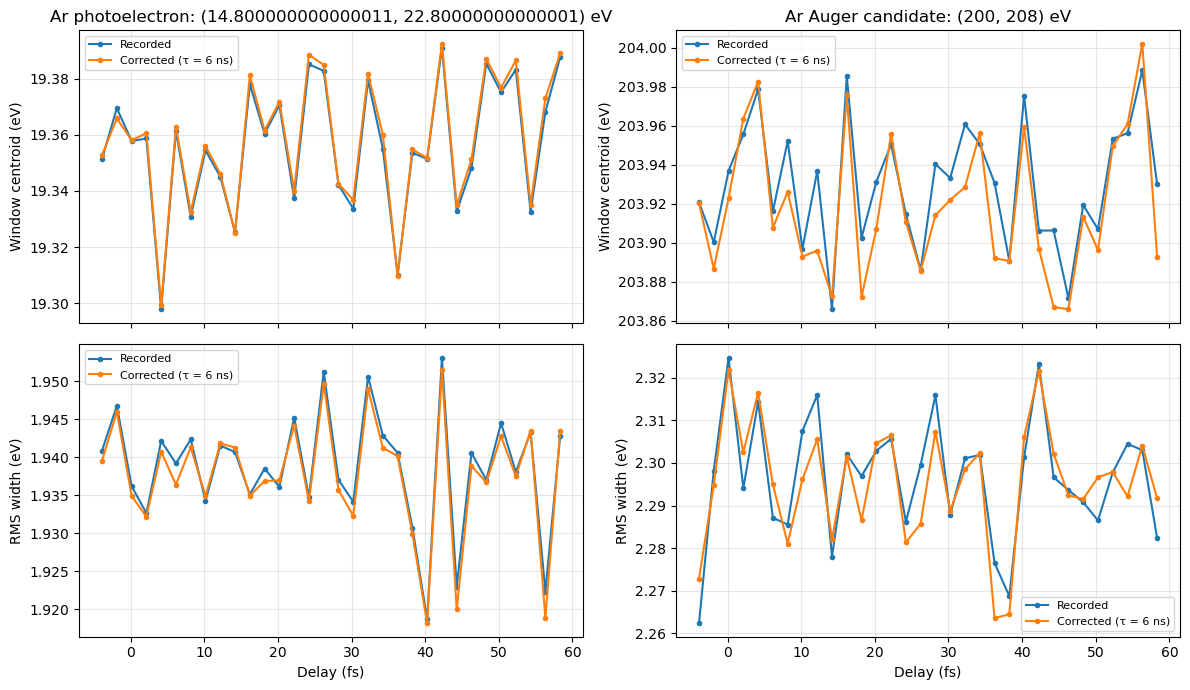

VLS calibration RMS (eV): 0.05345740058424091


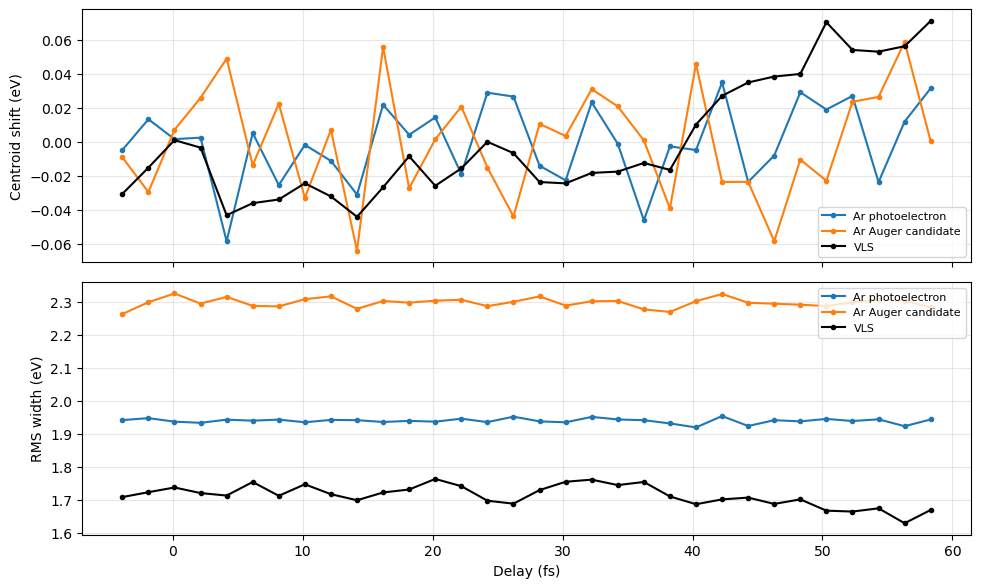

In [219]:
# ---- Local window moments ----------------------------------------------
fig, ax = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
peak_results = {}
for j, (label, win, sidebands) in enumerate([
        ('Ar photoelectron', AR_PHOTO, PHOTO_SIDEBANDS),
        ('Ar Auger candidate', AR_AUGER, AUGER_SIDEBANDS)]):
    gate = in_win(ke, *win)
    for name, e in curves:
        counts = e[:, gate].copy()
        if sidebands is not None:
            bg = np.zeros(len(ke), dtype=bool)
            for side in sidebands:
                bg |= in_win(ke, *side)
            if not bg.any() or np.any(bg & gate):
                raise ValueError(f'{label}: invalid sidebands')
            density = e[:, bg].sum(axis=1)/dke[bg].sum()
            counts = np.clip(counts-density[:, None]*dke[gate], 0, None)
        n = counts.sum(axis=1)
        centre = divide(counts @ ke[gate], n)
        width = np.sqrt(divide(np.sum(counts*(ke[gate]-centre[:, None])**2, axis=1), n))
        centre[electron_combined['n']<MIN_SHOTS] = np.nan
        width[electron_combined['n']<MIN_SHOTS] = np.nan
        peak_results[label, name] = (centre, width)
        ax[0, j].plot(delay, centre, '.-', label=name)
        ax[1, j].plot(delay, width, '.-', label=name)
    ax[0, j].set(title=f'{label}: {win} eV', ylabel='Window centroid (eV)')
    ax[1, j].set(xlabel='Delay (fs)', ylabel='RMS width (eV)')
for a in ax.flat:
    a.grid(alpha=0.3)
    a.legend(fontsize=8)
fig.tight_layout()
plt.show()

# VLS calibration from the same source notebook; optional if file is absent.
if VLS_CAL_FILE.is_file():
    with h5py.File(VLS_CAL_FILE, 'r') as f:
        cal_coef = f['photon_energy/cal_coef'][:]
        cal_px = f['photon_energy/cal_centres'][:]
        cal_E = f['photon_energy/cal_energies'][:]
    vls_energy = np.polyval(cal_coef, vls_pixels)
    print('VLS calibration RMS (eV):', np.sqrt(np.mean((np.polyval(cal_coef, cal_px)-cal_E)**2)))
    # Use the same integrated spectrum as the exposure; positive weights only for moments.
    weights = np.clip(vls_combined['a'], 0, None)
    vcentre = divide(weights @ vls_energy, weights.sum(axis=1))
    vwidth = np.sqrt(divide(np.sum(weights*(vls_energy-vcentre[:, None])**2, axis=1), weights.sum(axis=1)))
    fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
    name = curves[-1][0] if USE_READY else curves[0][0]
    for label in ('Ar photoelectron', 'Ar Auger candidate'):
        c, w = peak_results[label, name]
        ax[0].plot(delay, c-reference(c, combined['n']), '.-', label=label)
        ax[1].plot(delay, w, '.-', label=label)
    ax[0].plot(delay, vcentre-reference(vcentre, combined['n']), 'k.-', label='VLS')
    ax[1].plot(delay, vwidth, 'k.-', label='VLS')
    ax[0].set_ylabel('Centroid shift (eV)')
    ax[1].set(xlabel='Delay (fs)', ylabel='RMS width (eV)')
    for a in ax:
        a.grid(alpha=0.3)
        a.legend(fontsize=8)
    fig.tight_layout()
    plt.show()
else:
    print(f'VLS calibration unavailable: {VLS_CAL_FILE.name}; electron moments still available.')

Ar photoelectron (Recorded) vs. VLS centroid shift: Pearson r = 0.420 (n=32)
Ar Auger candidate (Recorded) vs. VLS centroid shift: Pearson r = 0.013 (n=32)


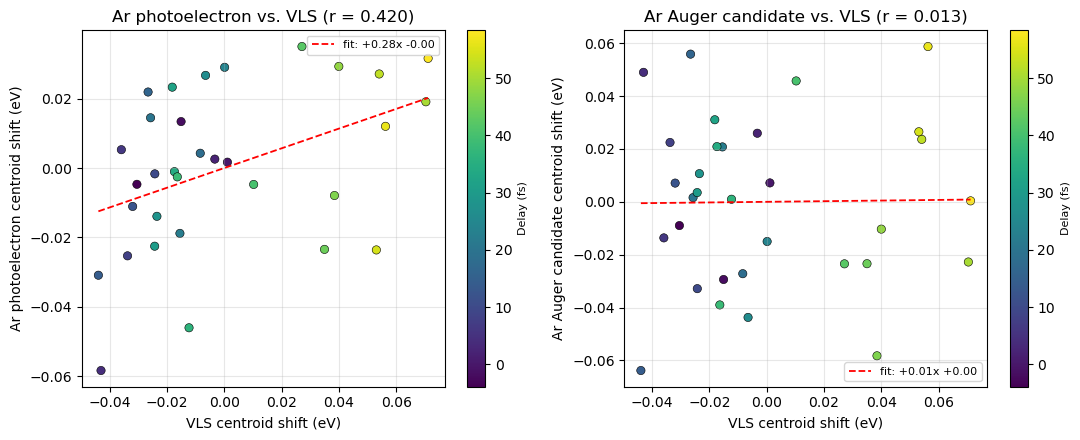

In [220]:
# ---- Centroid-shift correlation: VLS vs. Ar photoelectron & Auger ------
name = curves[-1][0] if USE_READY else curves[0][0]
v_shift = vcentre - reference(vcentre, combined['n'])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax_i, label in enumerate(('Ar photoelectron', 'Ar Auger candidate')):
    c, _ = peak_results[label, name]
    e_shift = c - reference(c, combined['n'])

    valid = np.isfinite(v_shift) & np.isfinite(e_shift)
    x = v_shift[valid]
    y = e_shift[valid]

    r = np.corrcoef(x, y)[0, 1] if len(x) > 1 else np.nan
    print(f'{label} ({name}) vs. VLS centroid shift: Pearson r = {r:.3f} (n={len(x)})')

    sc = axes[ax_i].scatter(x, y, c=delay[valid], cmap='viridis', s=36, edgecolors='k', linewidths=0.4)
    if len(x) > 1 and np.ptp(x) > 0:
        slope, intercept = np.polyfit(x, y, 1)
        x_line = np.linspace(x.min(), x.max(), 100)
        axes[ax_i].plot(x_line, slope * x_line + intercept, 'r--', lw=1.3, label=f'fit: {slope:+.2f}x {intercept:+.2f}')
        axes[ax_i].legend(fontsize=8)

    axes[ax_i].set(
        title=f'{label} vs. VLS (r = {r:.3f})',
        xlabel='VLS centroid shift (eV)',
        ylabel=f'{label} centroid shift (eV)',
    )
    axes[ax_i].grid(alpha=0.3)
    cbar = fig.colorbar(sc, ax=axes[ax_i])
    cbar.set_label('Delay (fs)', fontsize=8)

fig.tight_layout()
plt.show()

### 5.1	Ar²⁺-gated photoelectron centroid

Covariance estimator: partial on GMD
Covariance shots: 7,370,649
All electron shots: 7,370,649

Ar photoelectron gated on (19, 21) u/e
Accepted centroid bins: 32 / 32
Common bins for correlation: 32
Ordinary: slope = 0.284, r = 0.420
Gated: slope = 0.178, r = 0.075


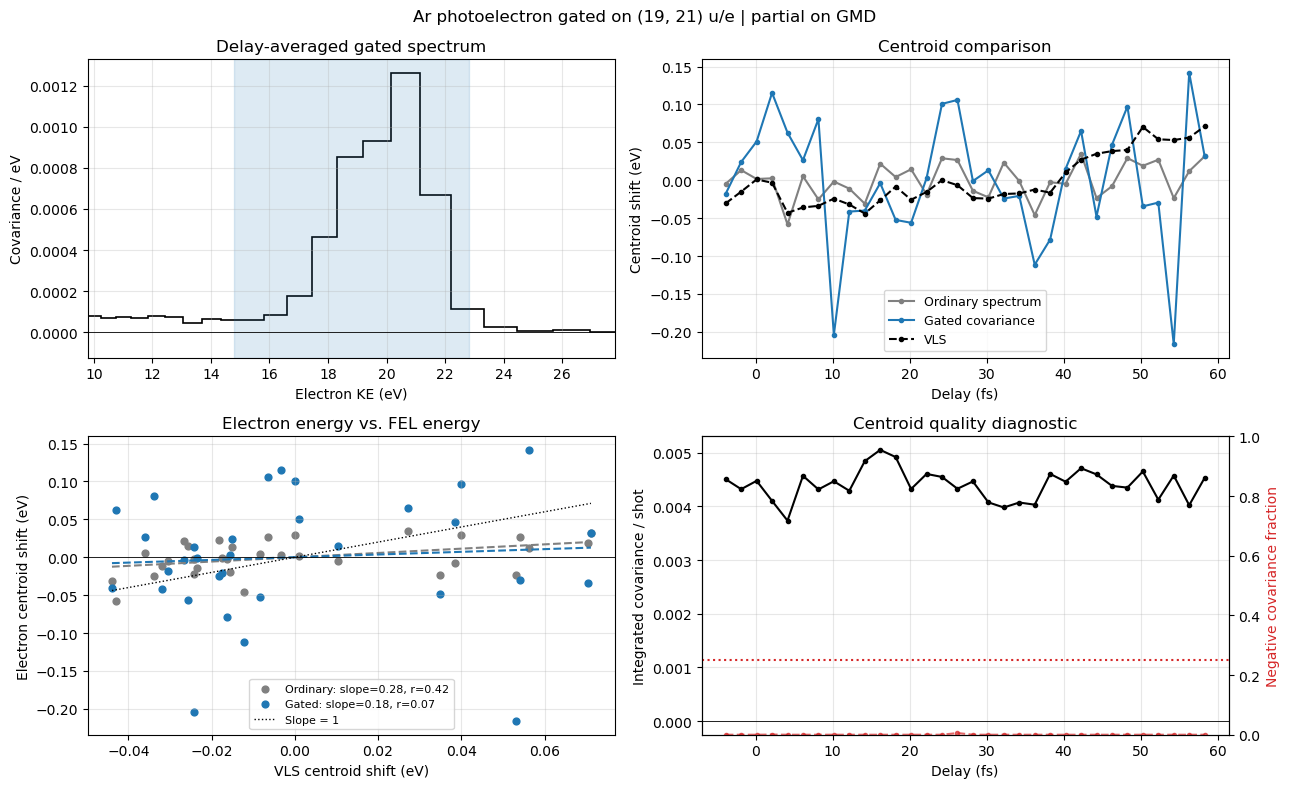

In [221]:
# ---- 5.1 Ar2+-gated photoelectron centroid -------------------------------

GATED_EST = 'partial on GMD'
GATED_PHOTO_SIDEBANDS = PHOTO_SIDEBANDS
MAX_NEGATIVE_FRACTION = 0.25

assert GATED_EST in base_methods and GATED_EST != 'total'
assert 'vls_energy' in globals(), 'Run section 5 VLS calibration first'

# Use the VLS spectra from exactly the cells accepted in the
# selected covariance estimator.
gated_n = n_by[GATED_EST]
gated_vls = np.zeros((len(delay), len(vls_energy)))
gated_n_check = np.zeros(len(delay))

for path in COV_FILES:
    records = [
        r for r in cell_records
        if r['run'] == path.name and r['method'] == GATED_EST
    ]

    with h5py.File(path, 'r') as f:
        for r in records:
            iz = r['iz']
            k = iz if DELAY_SIGN == 1 else len(delay) - 1 - iz

            gated_vls[iz] += r['n'] * f['A'][r['gmd_bin'], k]
            gated_n_check[iz] += r['n']

np.testing.assert_array_equal(gated_n_check, gated_n)

vls_weights = np.clip(gated_vls, 0, None)
gated_vcentre = divide(
    vls_weights @ vls_energy,
    vls_weights.sum(axis=1)
)

print(f'Covariance estimator: {GATED_EST}')
print(f'Covariance shots: {gated_n.sum():,.0f}')
print(f'All electron shots: {combined["n"].sum():,.0f}')


# Shared centroid and plotting routine for sections 5.1 and 5.2.
def plot_gated_centroid(Y, win, sidebands, label, ordinary_label):

    gate = in_win(cov_ke, *win)

    if gate.sum() < 2:
        raise ValueError(f'{label}: too few energy bins in the gate')

    # Y contains covariance per energy bin, not density.
    counts = Y[:, gate].copy()

    # Optional local background subtraction.
    if sidebands is not None:
        bg = np.zeros(len(cov_ke), dtype=bool)

        for side in sidebands:
            bg |= in_win(cov_ke, *side)

        if not bg.any() or np.any(bg & gate):
            raise ValueError('Invalid background sidebands')

        bg_density = Y[:, bg].sum(axis=1) / cov_dke[bg].sum()
        counts -= bg_density[:, None] * cov_dke[gate]

    # Covariance is signed. Do not simply clip negative values
    # to zero, as that can create a positive noise background.
    area = counts.sum(axis=1)

    negative = np.maximum(-counts, 0).sum(axis=1)
    absolute = np.abs(counts).sum(axis=1)
    negative_fraction = divide(negative, absolute)

    centre = divide(counts @ cov_ke[gate], area)

    good = (
        (gated_n >= MIN_COV_SHOTS)
        & (area > 0)
        & (negative_fraction <= MAX_NEGATIVE_FRACTION)
        & (centre >= win[0])
        & (centre <= win[1])
        & np.isfinite(centre)
    )

    centre[~good] = np.nan

    ordinary_name = curves[-1][0] if USE_READY else curves[0][0]
    ordinary_centre = peak_results[ordinary_label, ordinary_name][0]

    # Same delay bins for the ordinary and gated correlations.
    valid = (
        good
        & np.isfinite(gated_vcentre)
        & np.isfinite(ordinary_centre)
    )

    weights = np.where(valid, gated_n, 0)

    v_shift = gated_vcentre - reference(gated_vcentre, weights)
    c_shift = centre - reference(centre, weights)
    o_shift = ordinary_centre - reference(ordinary_centre, weights)

    print(f'\n{label}')
    print(f'Accepted centroid bins: {good.sum()} / {len(delay)}')
    print(f'Common bins for correlation: {valid.sum()}')

    fig, ax = plt.subplots(2, 2, figsize=(13, 8))

    # Average gated spectrum.
    use = (gated_n > 0) & np.all(np.isfinite(Y[:, gate]), axis=1)

    if not use.any():
        raise ValueError('No finite gated covariance spectra')

    average = np.average(Y[use], axis=0, weights=gated_n[use])

    ax[0, 0].stairs(
        average / cov_dke,
        cov_ke_edges,
        color='k',
        lw=1.2
    )

    ax[0, 0].axvspan(*win, color='C0', alpha=0.15)
    ax[0, 0].axhline(0, color='k', lw=0.6)

    if sidebands is not None:
        for side in sidebands:
            ax[0, 0].axvspan(*side, color='C3', alpha=0.12)

    ax[0, 0].set(
        xlabel='Electron KE (eV)',
        ylabel='Covariance / eV',
        title='Delay-averaged gated spectrum',
        xlim=(win[0] - 5, win[1] + 5)
    )

    # Centroid shift against delay.
    ax[0, 1].plot(delay, o_shift, '.-', color='0.5',
                  label='Ordinary spectrum')
    ax[0, 1].plot(delay, c_shift, '.-', color='C0',
                  label='Gated covariance')
    ax[0, 1].plot(delay, v_shift, 'k.--', label='VLS')

    ax[0, 1].set(
        xlabel='Delay (fs)',
        ylabel='Centroid shift (eV)',
        title='Centroid comparison'
    )
    ax[0, 1].legend(fontsize=9)

    # Correlation with FEL photon-energy variations.
    x = v_shift[valid]

    for y, colour, name in [
        (o_shift, '0.5', 'Ordinary'),
        (c_shift, 'C0', 'Gated')
    ]:
        yy = y[valid]

        if len(x) < 3 or np.ptp(x) == 0 or np.ptp(yy) == 0:
            print(f'{name}: insufficient centroid variation for fit')
            continue

        slope, intercept = np.polyfit(x, yy, 1)
        r = np.corrcoef(x, yy)[0, 1]

        print(f'{name}: slope = {slope:.3f}, r = {r:.3f}')

        ax[1, 0].scatter(
            x, yy, s=24, color=colour,
            label=f'{name}: slope={slope:.2f}, r={r:.2f}'
        )

        xx = np.linspace(x.min(), x.max(), 100)
        ax[1, 0].plot(xx, slope * xx + intercept,
                      '--', color=colour)

    if len(x) >= 2 and np.ptp(x) > 0:
        xx = np.linspace(x.min(), x.max(), 100)
        ax[1, 0].plot(xx, xx, 'k:', lw=1, label='Slope = 1')

    ax[1, 0].axhline(0, color='k', lw=0.6)
    ax[1, 0].set(
        xlabel='VLS centroid shift (eV)',
        ylabel='Electron centroid shift (eV)',
        title='Electron energy vs. FEL energy'
    )
    ax[1, 0].legend(fontsize=8)

    # Check whether the centroid is based on a positive peak.
    ax[1, 1].plot(delay, area, 'k.-', label='Net covariance')
    ax[1, 1].axhline(0, color='k', lw=0.6)
    ax[1, 1].set(
        xlabel='Delay (fs)',
        ylabel='Integrated covariance / shot',
        title='Centroid quality diagnostic'
    )

    ax_r = ax[1, 1].twinx()
    ax_r.plot(delay, negative_fraction, 'C3.--', alpha=0.7)
    ax_r.axhline(MAX_NEGATIVE_FRACTION, color='C3', ls=':')
    ax_r.set_ylabel('Negative covariance fraction', color='C3')
    ax_r.set_ylim(0, 1)

    for a in ax.flat:
        a.grid(alpha=0.3)

    fig.suptitle(f'{label} | {GATED_EST}')
    fig.tight_layout()
    plt.show()

    return centre, area, negative_fraction


# EI covariance: (delay, electron KE, ion m/q).
ion_gate = in_win(cov_mq, *AR_ION)

if not ion_gate.any():
    raise ValueError('Empty Ar2+ ion gate')

ar_photo_ei = EST[GATED_EST]['DC'][:, :, ion_gate].sum(axis=2)

ar_photo_centre_ei, ar_photo_area_ei, ar_photo_neg_ei = (
    plot_gated_centroid(
        ar_photo_ei,
        AR_PHOTO,
        GATED_PHOTO_SIDEBANDS,
        f'Ar photoelectron gated on {AR_ION} u/e',
        'Ar photoelectron'
    )
)

### # ---- 5.2 Ar-photoelectron-gated Auger centroid --------------------------


Ar Auger gated on (14.800000000000011, 22.80000000000001) eV
Accepted centroid bins: 32 / 32
Common bins for correlation: 32
Ordinary: slope = 0.012, r = 0.013
Gated: slope = -0.288, r = -0.109


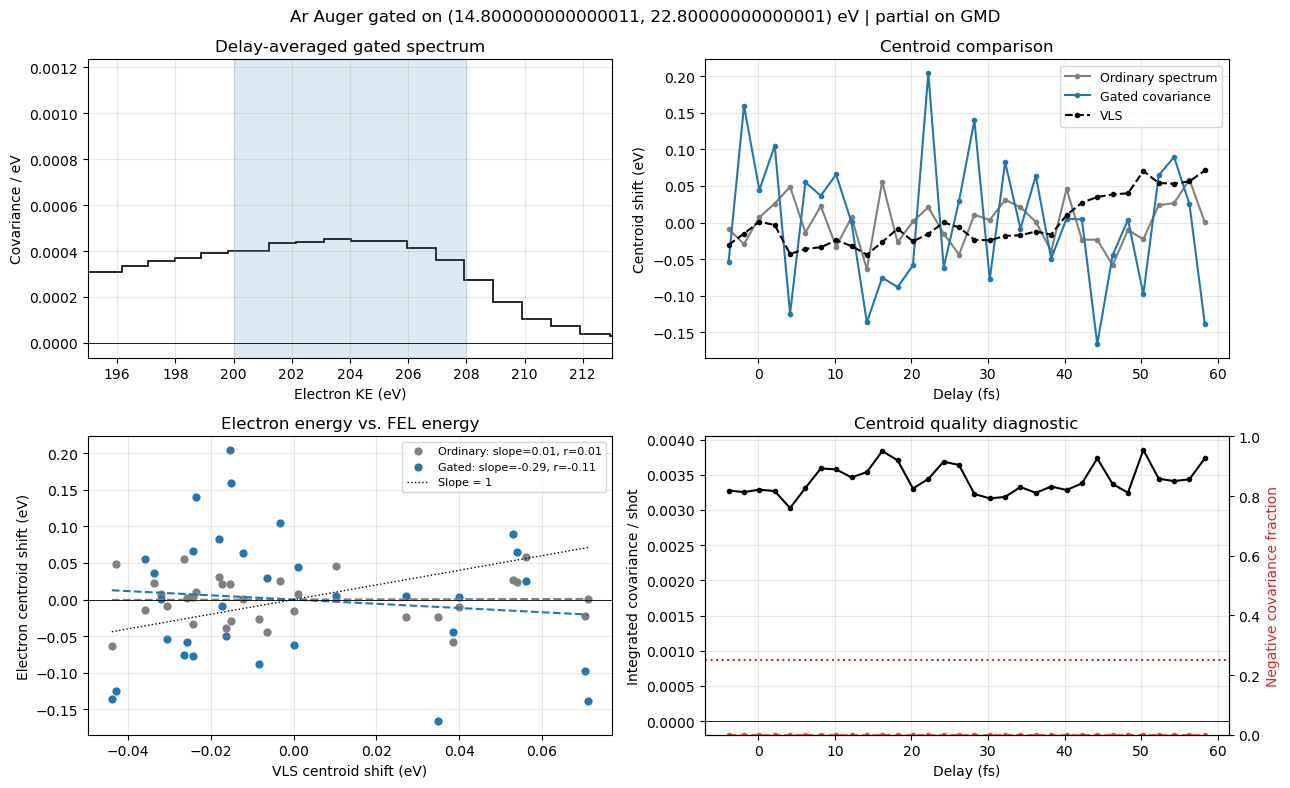

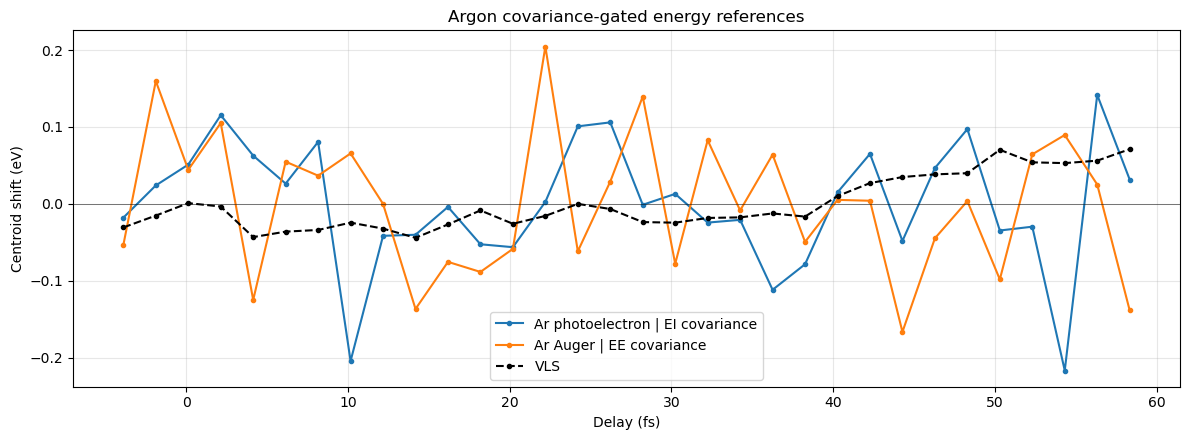

In [222]:
# ---- 5.2 Ar-photoelectron-gated Auger centroid --------------------------

GATED_AUGER_SIDEBANDS = AUGER_SIDEBANDS

photo_gate = in_win(cov_ke, *AR_PHOTO)

if not photo_gate.any():
    raise ValueError('Empty Ar photoelectron gate')

# Existing notebook helper excludes the dead-time band.
ar_auger_ee = ee_gated(
    EST[GATED_EST]['DD'],
    photo_gate
)

ar_auger_centre_ee, ar_auger_area_ee, ar_auger_neg_ee = (
    plot_gated_centroid(
        ar_auger_ee,
        AR_AUGER,
        GATED_AUGER_SIDEBANDS,
        f'Ar Auger gated on {AR_PHOTO} eV',
        'Ar Auger candidate'
    )
)


# ---- Direct comparison of the two covariance-gated centroids -----------

fig, ax = plt.subplots(figsize=(12, 4.5))

ax.plot(
    delay,
    ar_photo_centre_ei - reference(ar_photo_centre_ei, gated_n),
    'C0.-',
    label='Ar photoelectron | EI covariance'
)

ax.plot(
    delay,
    ar_auger_centre_ee - reference(ar_auger_centre_ee, gated_n),
    'C1.-',
    label='Ar Auger | EE covariance'
)

ax.plot(
    delay,
    gated_vcentre - reference(gated_vcentre, gated_n),
    'k.--',
    label='VLS'
)

ax.axhline(0, color='k', lw=0.7, alpha=0.5)

ax.set(
    xlabel='Delay (fs)',
    ylabel='Centroid shift (eV)',
    title='Argon covariance-gated energy references'
)

ax.grid(alpha=0.3)
ax.legend()

fig.tight_layout()
plt.show()

Photon-energy reference: 268.7510 eV


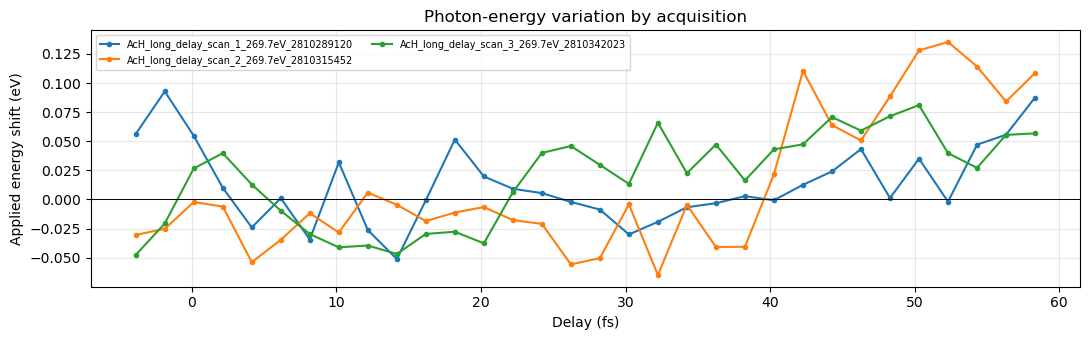

Shots retained: 7,370,649
Total selected shots: 7,370,649
Fraction of counts retained after shifting: 0.9921419315350242
Median KE bin width in molecular region: 1.1185105201291492 eV


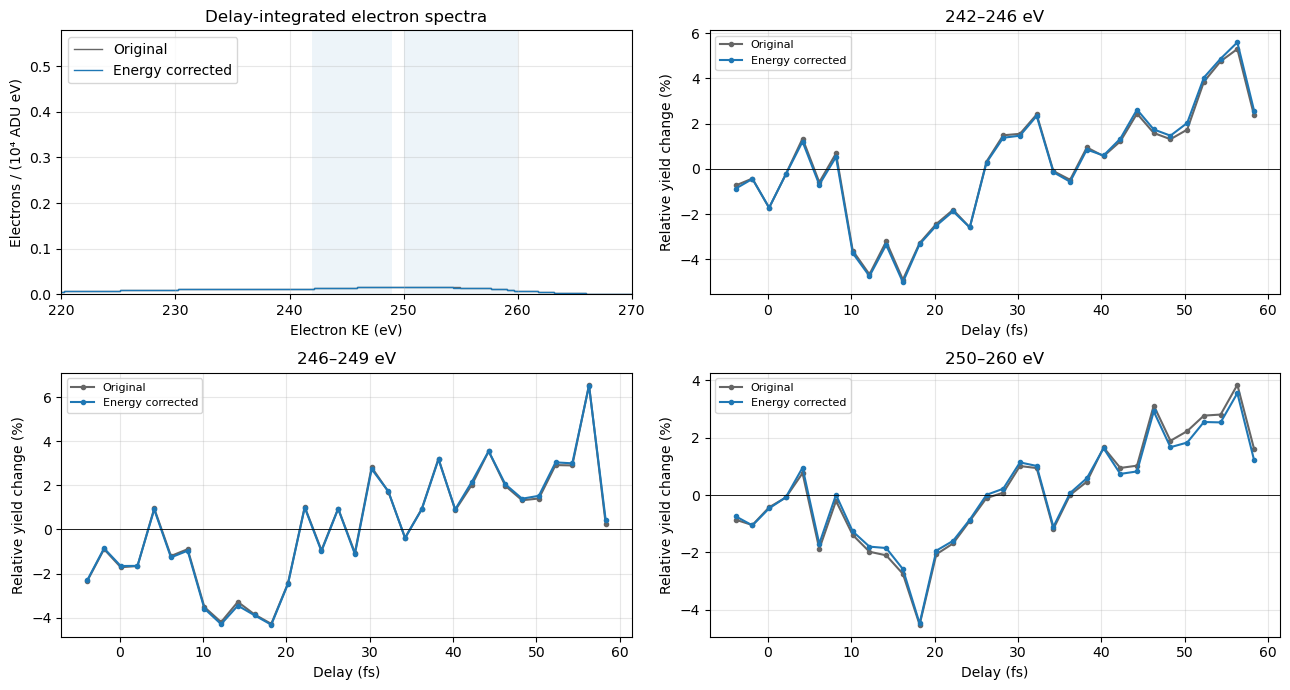

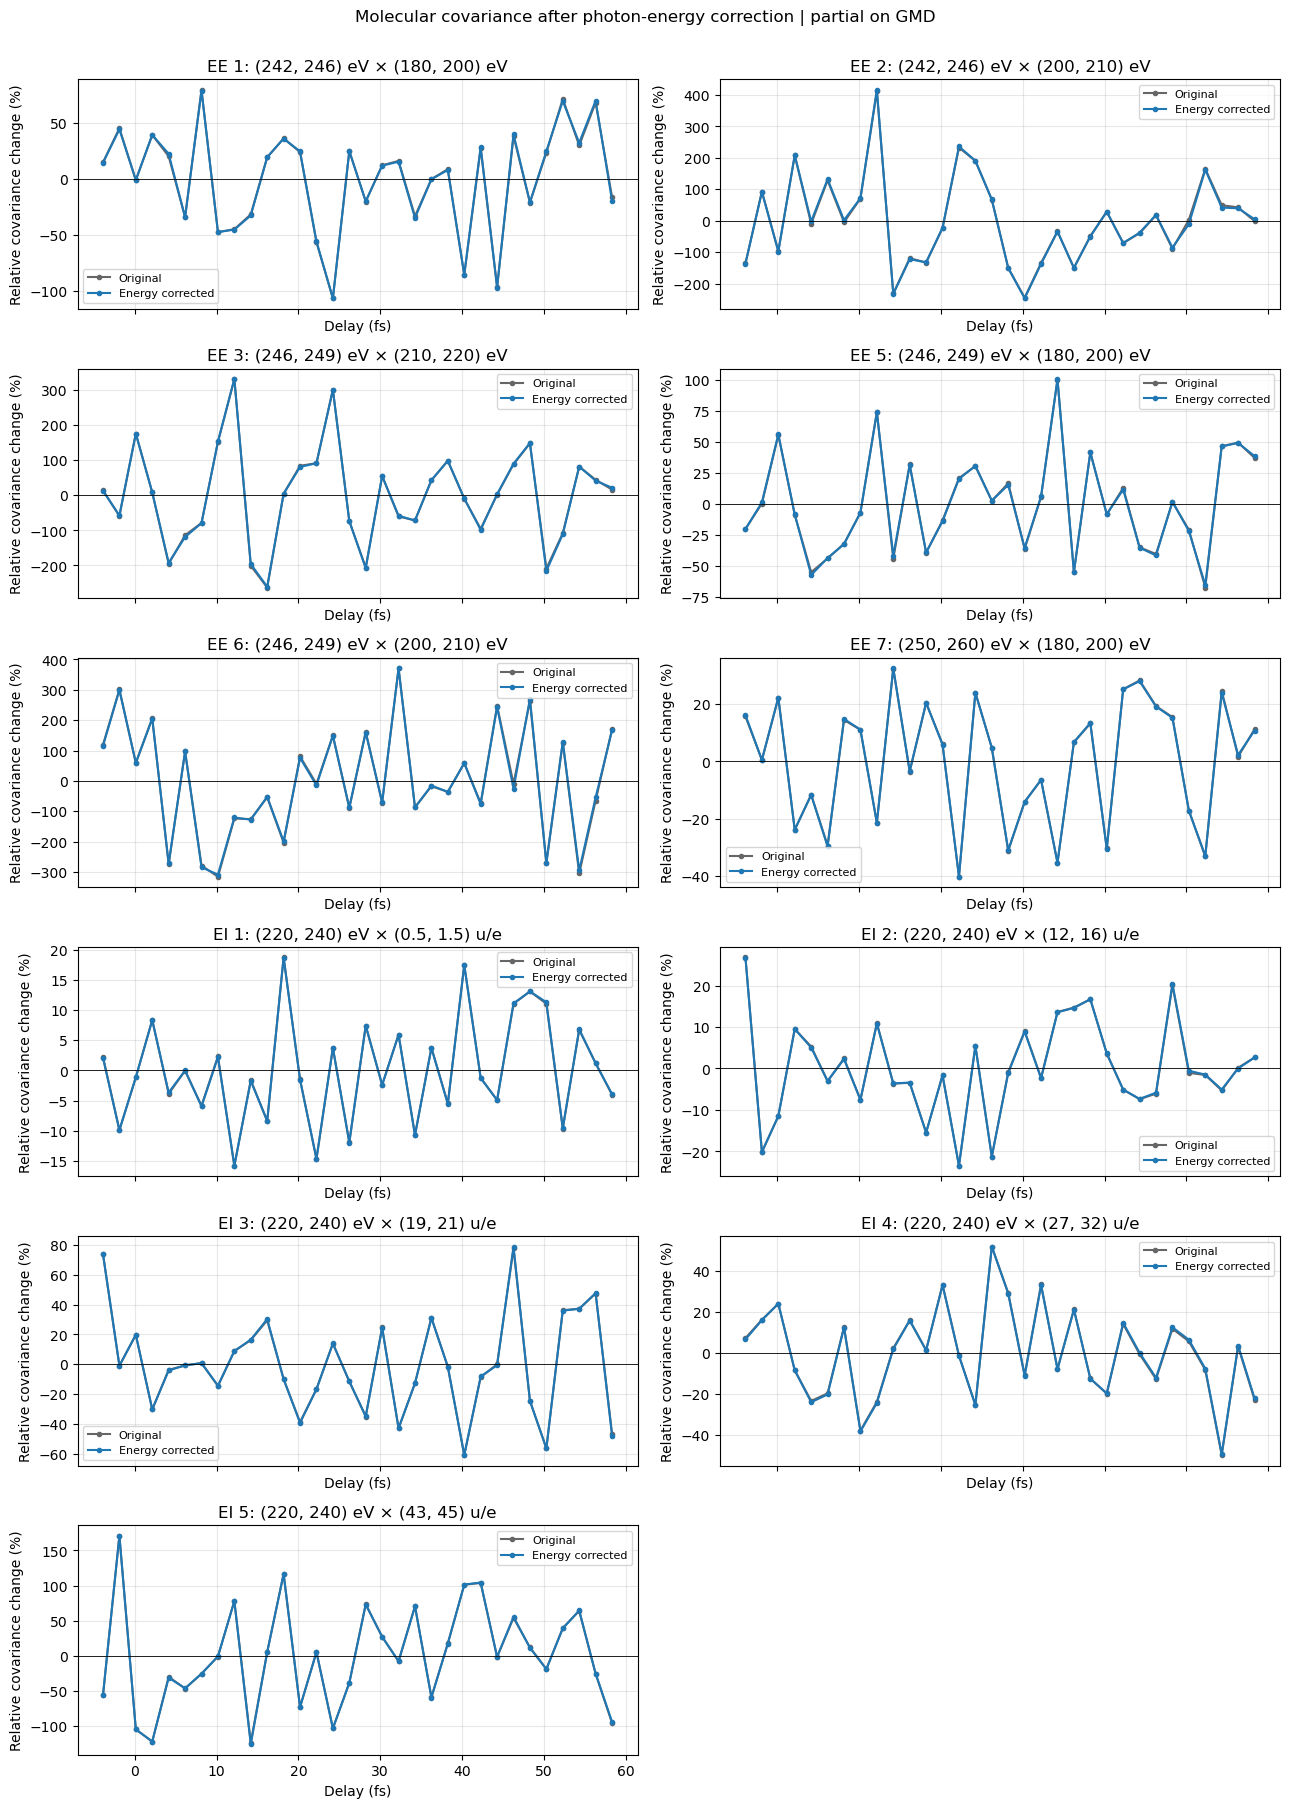

In [223]:
# ---- 5.3 FEL photon-energy correction of molecular spectra ---------------

SHIFT_SCALE = 1.0
SHIFT_KE_LIM = (220, 270)

SHIFT_WINDOWS = [
    (242, 246),
    (246, 249),
    (250, 260)
]

hv_ref = reference(vcentre, combined['n'])

if not np.isfinite(hv_ref):
    raise ValueError('No valid VLS reference energy')

print(f'Photon-energy reference: {hv_ref:.4f} eV')

# Fraction of each energy bin inside an ROI.
# Used for both original and shifted integrations.
def roi_weights(edges, win):
    lo, hi = win

    overlap = (
        np.minimum(edges[1:], hi)
        - np.maximum(edges[:-1], lo)
    )

    return np.clip(overlap, 0, None) / np.diff(edges)


# ---- A. Ordinary electron spectra --------------------------------------

e_before = np.zeros_like(electron_combined['e'], dtype=float)
e_after = np.zeros_like(e_before)

shift_exposure = np.zeros(len(delay))
shift_shots = np.zeros(len(delay))

fig, ax = plt.subplots(figsize=(11, 3.5))

for run, s in electron_scans.items():

    # Calculate the VLS centroid independently for each acquisition.
    vls = np.clip(vls_scans[run]['a'], 0, None)

    hv_run = divide(
        vls @ vls_energy,
        vls.sum(axis=1)
    )

    delta = SHIFT_SCALE * (hv_run - hv_ref)

    exposure = s[electron_exposure_key]

    valid = (
        (s['n'] >= MIN_SHOTS)
        & np.isfinite(delta)
        & np.isfinite(exposure)
        & (exposure > 0)
    )

    ax.plot(
        delay,
        np.where(valid, delta, np.nan),
        '.-',
        label=run.split('_aggregates')[0]
    )

    for k in np.flatnonzero(valid):

        counts = s['e'][k]

        # Integrated counts at the original energy-bin edges.
        cumulative = np.r_[0, np.cumsum(counts)]

        # A positive photon-energy shift requires moving the
        # measured photoelectron spectrum towards lower KE.
        cumulative_shifted = np.interp(
            ke_edges + delta[k],
            ke_edges,
            cumulative
        )

        counts_shifted = np.diff(cumulative_shifted)

        e_before[k] += counts
        e_after[k] += counts_shifted

        shift_exposure[k] += exposure[k]
        shift_shots[k] += s['n'][k]

ax.axhline(0, color='k', lw=0.7)
ax.set(
    xlabel='Delay (fs)',
    ylabel='Applied energy shift (eV)',
    title='Photon-energy variation by acquisition'
)
ax.grid(alpha=0.3)
ax.legend(fontsize=7, ncol=2)

fig.tight_layout()
plt.show()

if not shift_exposure.any():
    raise ValueError('No valid spectra for energy correction')

print(f'Shots retained: {shift_shots.sum():,.0f}')
print(f'Total selected shots: {combined["n"].sum():,.0f}')

print(
    'Fraction of counts retained after shifting:',
    e_after.sum() / e_before.sum()
)

print(
    'Median KE bin width in molecular region:',
    np.median(dke[in_win(ke, *SHIFT_KE_LIM)]),
    'eV'
)


# ---- Compare electron spectra and yield traces -------------------------

fig, ax = plt.subplots(2, 2, figsize=(13, 7))
ax = ax.ravel()

before_average = (
    e_before.sum(axis=0) / shift_exposure.sum() / dke
)

after_average = (
    e_after.sum(axis=0) / shift_exposure.sum() / dke
)

ax[0].stairs(
    before_average, ke_edges,
    color='0.4', label='Original'
)

ax[0].stairs(
    after_average, ke_edges,
    color='C0', label='Energy corrected'
)

for win in SHIFT_WINDOWS:
    ax[0].axvspan(*win, alpha=0.08)

ax[0].set(
    xlabel='Electron KE (eV)',
    ylabel=f'Electrons / ({electron_unit} eV)',
    title='Delay-integrated electron spectra',
    xlim=SHIFT_KE_LIM
)

ax[0].legend()

for j, win in enumerate(SHIFT_WINDOWS, start=1):

    weights = roi_weights(ke_edges, win)

    y_before = divide(e_before @ weights, shift_exposure)
    y_after = divide(e_after @ weights, shift_exposure)

    ax[j].plot(
        delay, relative(y_before, shift_exposure),
        '.-', color='0.4', label='Original'
    )

    ax[j].plot(
        delay, relative(y_after, shift_exposure),
        '.-', color='C0', label='Energy corrected'
    )

    ax[j].axhline(0, color='k', lw=0.6)

    ax[j].set(
        xlabel='Delay (fs)',
        ylabel='Relative yield change (%)',
        title=f'{win[0]}–{win[1]} eV'
    )

    ax[j].legend(fontsize=8)

for a in ax:
    a.grid(alpha=0.3)

fig.tight_layout()
plt.show()


# ---- B. Photon-energy correction of molecular covariance ROIs ----------

# EST contains covariance already pooled across acquisitions.
# Use the matched VLS centroid from section 5.1.
# Shift the candidate photoelectron gate only.
# Keep the correlated electron/ion gate fixed.

cov_delta = SHIFT_SCALE * (gated_vcentre - hv_ref)

cov_valid = (
    (gated_n >= MIN_COV_SHOTS)
    & np.isfinite(cov_delta)
)

molecular_labels = [
    label for label in roi_masks
    if label.startswith(('EE ', 'EI '))
]

if not molecular_labels:
    raise ValueError('No molecular covariance ROIs available')

nrows = (len(molecular_labels) + 1) // 2

fig, ax = plt.subplots(
    nrows, 2,
    figsize=(13, 3.0 * nrows),
    sharex=True,
    squeeze=False
)

ax = ax.ravel()
energy_corrected_rois = {}

for j, label in enumerate(molecular_labels):

    kind, win1, win2 = roi_defs[label]

    w1 = roi_weights(cov_ke_edges, win1)

    if kind == 'DD':
        w2 = roi_weights(cov_ke_edges, win2)
    else:
        w2 = roi_weights(cov_mq_edges, win2)

    before = np.full(len(delay), np.nan)
    after = np.full(len(delay), np.nan)

    for k in np.flatnonzero(cov_valid):

        M = EST[GATED_EST][kind][k]

        if kind == 'DD':
            # Keep the original pair dead-time exclusion.
            M = np.where(band, 0, M)

        # To correct a positive photon-energy shift,
        # integrate the original covariance at higher KE.
        shifted_win1 = (
            win1[0] + cov_delta[k],
            win1[1] + cov_delta[k]
        )

        w1_shifted = roi_weights(
            cov_ke_edges, shifted_win1
        )

        before[k] = w1 @ M @ w2
        after[k] = w1_shifted @ M @ w2

    if COV_NORMALISE_GMD:
        mean_gmd = divide(g_by[GATED_EST], gated_n)

        before = divide(before, mean_gmd)
        after = divide(after, mean_gmd)

    energy_corrected_rois[label] = {
        'original': before,
        'corrected': after
    }

    ax[j].plot(
        delay,
        relative(before, gated_n),
        '.-', color='0.4',
        label='Original'
    )

    ax[j].plot(
        delay,
        relative(after, gated_n),
        '.-', color='C0',
        label='Energy corrected'
    )

    ax[j].axhline(0, color='k', lw=0.6)

    unit2 = 'eV' if kind == 'DD' else 'u/e'

    ax[j].set(
        title=f'{label}: {win1} eV × {win2} {unit2}',
        xlabel='Delay (fs)',
        ylabel='Relative covariance change (%)'
    )

    ax[j].grid(alpha=0.3)
    ax[j].legend(fontsize=8)

for a in ax[len(molecular_labels):]:
    a.set_visible(False)

fig.suptitle(
    f'Molecular covariance after photon-energy correction'
    f' | {GATED_EST}',
    y=1.002
)

fig.tight_layout()
plt.show()

## 6. Partial covariance on argon
For recorded Ar count $A$, subtract $\mathrm{cov}(X,A)\mathrm{cov}(A,Y)/\mathrm{var}(A)$ from the within-cell covariance. Compare the molecular ROIs to GMD and VLS correction. This can remove real molecular signal if the Ar gate overlaps molecular electrons or responds to the same physical process. Ar counting noise, saturation and detector effects also limit it. The conditioned Ar trace is suppressed by construction; **do not use that suppression as evidence of improved physics**. Use a separate holdout channel if one can be identified.

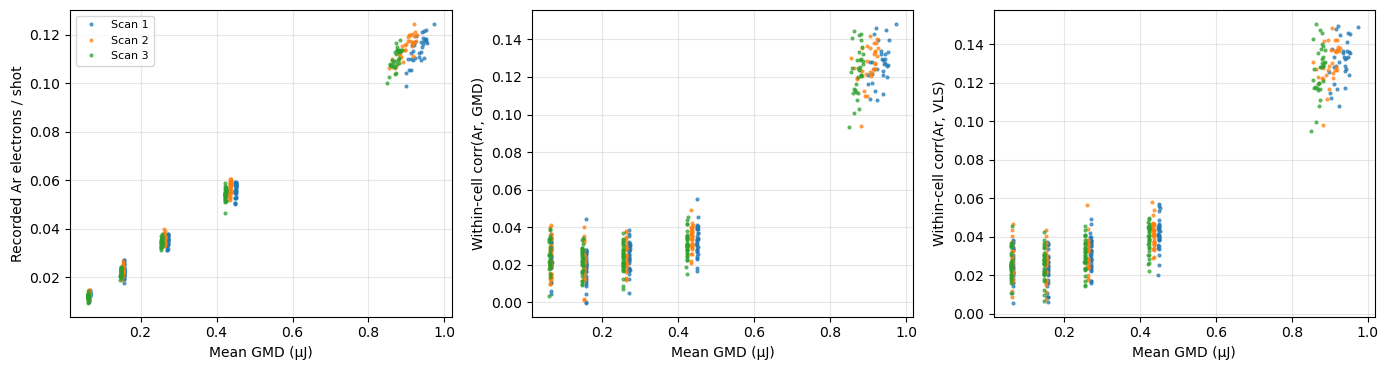

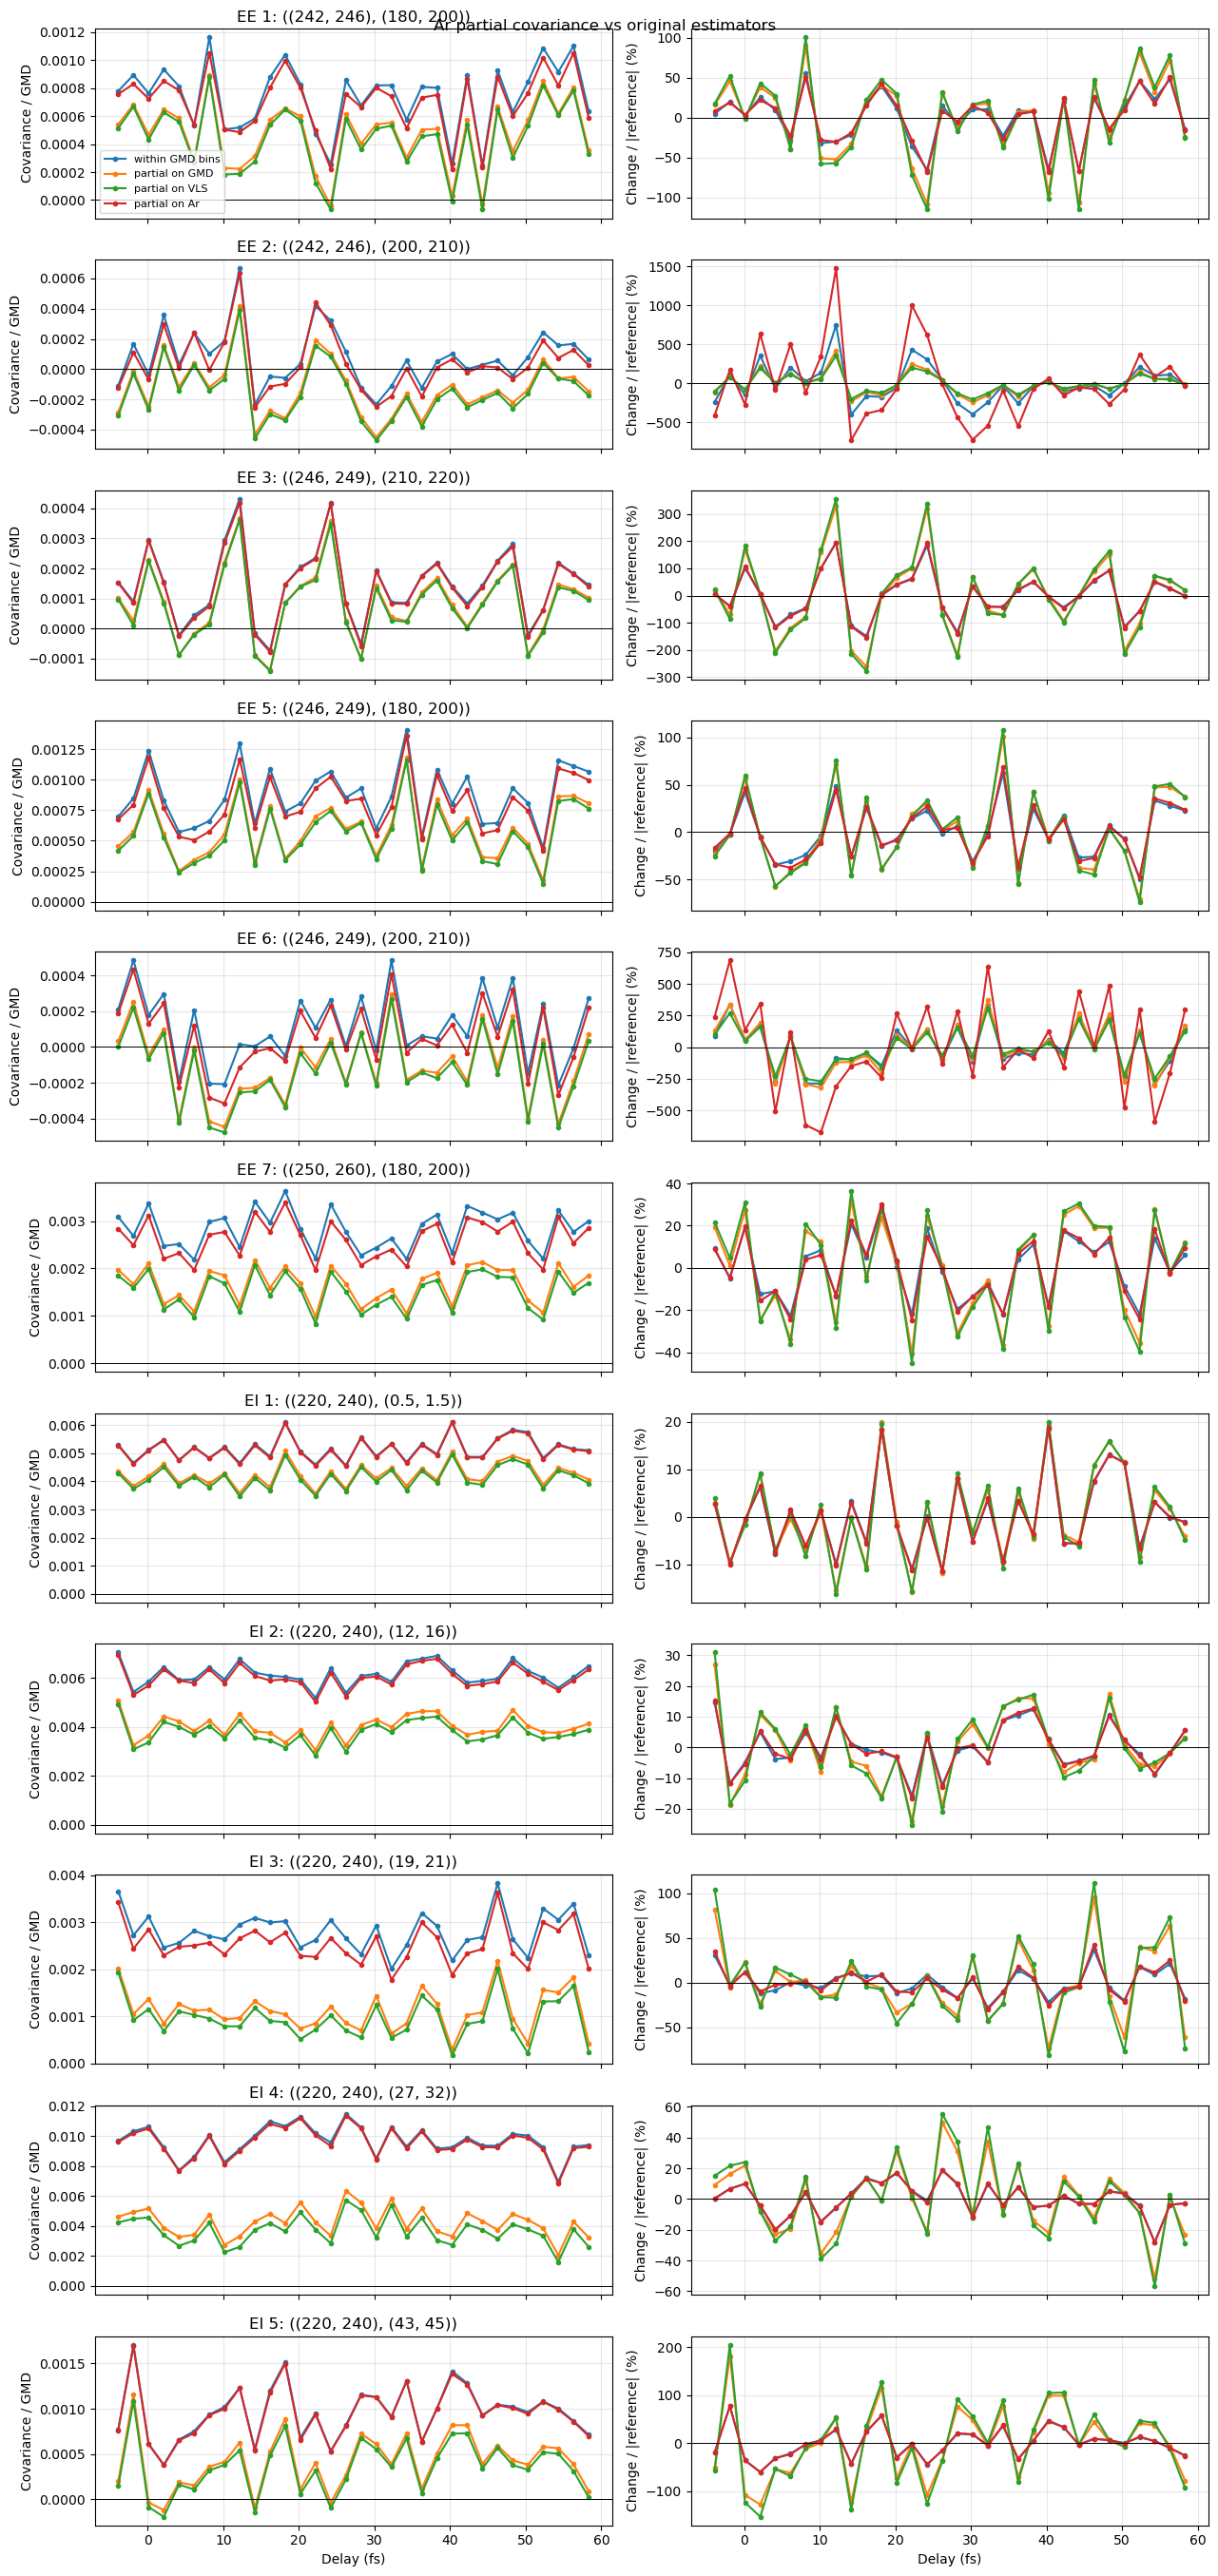

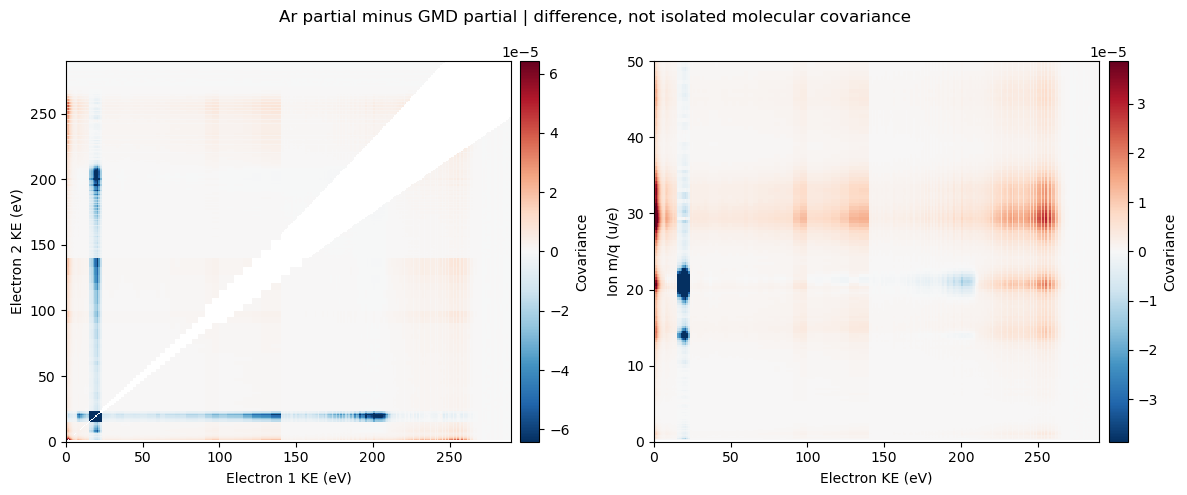

In [224]:
# How much Ar is actually detected per shot? How well does it track the monitors?
# Each point is a GMD-delay cell; correlations are within that cell, not across delays.
if monitor_records:
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
    for i, path in enumerate(COV_FILES):
        rr = [r for r in monitor_records if r['run']==path.name]
        x = [r['gmd'] for r in rr]
        for a, key in zip(ax, ('ar', 'GMD', 'VLS')):
            a.plot(x, [r[key] for r in rr], '.', ms=4, alpha=0.65, label=f'Scan {i+1}')
    ax[0].set_ylabel('Recorded Ar electrons / shot')
    ax[1].set_ylabel('Within-cell corr(Ar, GMD)')
    ax[2].set_ylabel('Within-cell corr(Ar, VLS)')
    for a in ax:
        a.set_xlabel('Mean GMD (µJ)')
        a.grid(alpha=0.3)
    ax[0].legend(fontsize=8)
    fig.tight_layout()
    plt.show()

if 'partial on Ar' not in EST_AV:
    print('Ar correction not available. Enable RUN_AR_COV and check coverage.')
else:
    compare = [m for m in ('within GMD bins', 'partial on GMD', 'partial on VLS', 'partial on Ar') if m in EST_AV]
    labels = [l for l in roi_masks if not l.startswith('Ar')]
    fig, ax = plt.subplots(len(labels), 2, figsize=(13, 2.5*len(labels)), sharex=True, squeeze=False)
    for j, label in enumerate(labels):
        for name in compare:
            y = roi_trace(name, label)
            ax[j, 0].plot(delay, y, '.-', label=name)
            ax[j, 1].plot(delay, relative(y, n_by[name]), '.-', label=name)
        ax[j, 0].set(title=f'{label}: {roi_defs[label][1:]}', ylabel=cov_label)
        ax[j, 1].set_ylabel('Change / |reference| (%)')
    for a in ax.flat:
        a.grid(alpha=0.3)
        a.axhline(0, color='k', lw=0.7)
    ax[0, 0].legend(fontsize=8)
    for a in ax[-1]:
        a.set_xlabel('Delay (fs)')
    fig.suptitle('Ar partial covariance vs original estimators')
    fig.tight_layout()
    plt.show()

    # Difference maps: useful to see which spectral regions are removed.
    if 'partial on GMD' in EST_AV:
        E0, E1 = EST_AV['partial on GMD'], EST_AV['partial on Ar']
        fig, ax = plt.subplots(1, 2, figsize=(12, 5))
        show_cov_map(ax[0], np.where(band, np.nan, E1['DD']-E0['DD']).T, cov_ke_edges, cov_ke_edges)
        show_cov_map(ax[1], (E1['DC']-E0['DC']).T, cov_ke_edges, cov_mq_edges)
        ax[0].set(xlabel='Electron 1 KE (eV)', ylabel='Electron 2 KE (eV)', xlim=COV_KE_LIM, ylim=COV_KE_LIM)
        ax[1].set(xlabel='Electron KE (eV)', ylabel='Ion m/q (u/e)', xlim=COV_KE_LIM, ylim=COV_MQ_LIM)
        fig.suptitle('Ar partial minus GMD partial | difference, not isolated molecular covariance')
        fig.tight_layout()
        plt.show()

## 7. Multivariable partial covariance
Compare partial covariance on GMD + Ar, VLS + Ar and, if the GMD–VLS moment is present, all three. The correction is calculated jointly, not by subtracting the single-monitor corrections separately. Monitor covariance inversion is performed cell by cell with the condition-number check in the preparation section. A smaller signal or smoother trace does not automatically mean a better correction. Use independent runs and a control gate outside the conditioning gate.

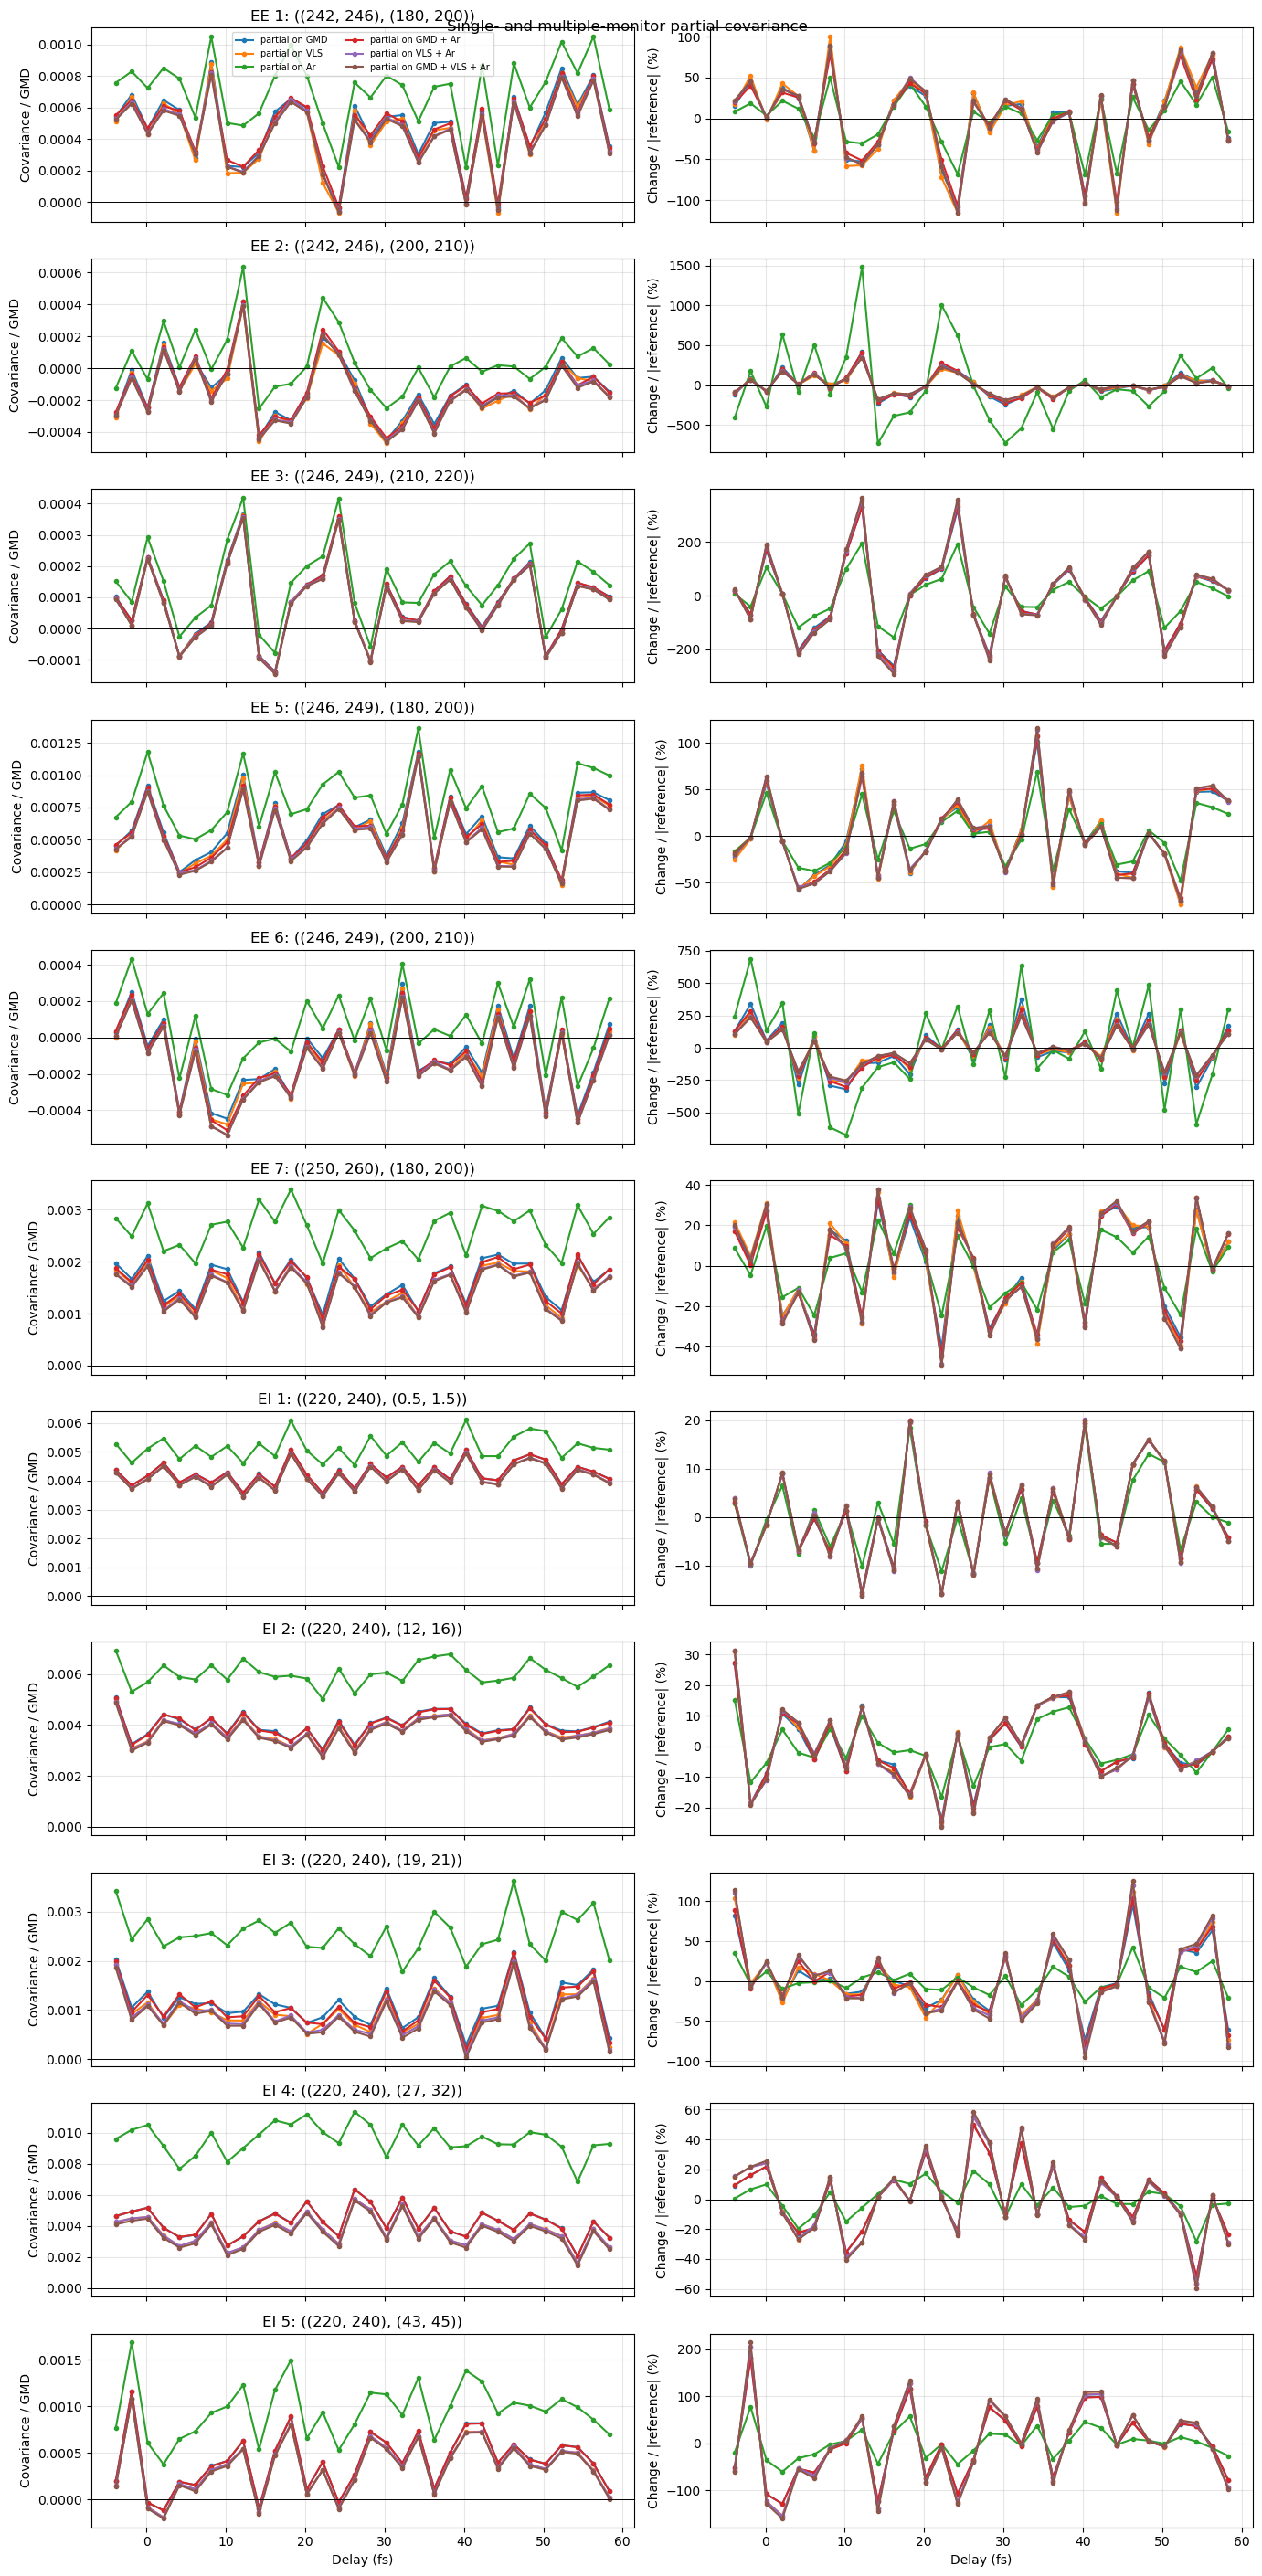

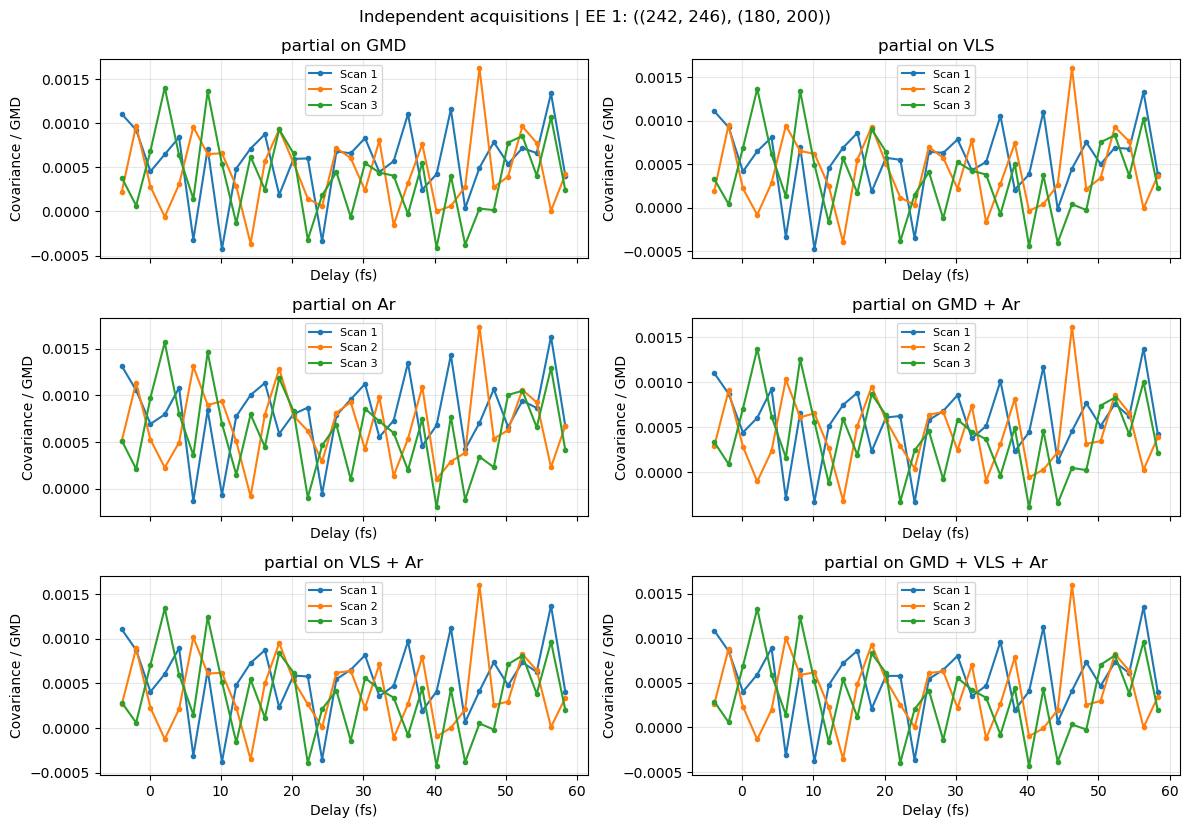

In [225]:
compare = [m for m in EST_AV if m.startswith('partial on')]
if not any(' + ' in m for m in compare):
    print('No multivariable correction available; check flags and monitor moments.')
else:
    labels = [l for l in roi_masks if not l.startswith('Ar')]
    fig, ax = plt.subplots(len(labels), 2, figsize=(14, 2.6*len(labels)), sharex=True, squeeze=False)
    for j, label in enumerate(labels):
        for name in compare:
            y = roi_trace(name, label)
            ax[j, 0].plot(delay, y, '.-', label=name)
            ax[j, 1].plot(delay, relative(y, n_by[name]), '.-', label=name)
        ax[j, 0].set(title=f'{label}: {roi_defs[label][1:]}', ylabel=cov_label)
        ax[j, 1].set_ylabel('Change / |reference| (%)')
    for a in ax.flat:
        a.axhline(0, color='k', lw=0.7)
        a.grid(alpha=0.3)
    ax[0, 0].legend(fontsize=7, ncol=2)
    for a in ax[-1]:
        a.set_xlabel('Delay (fs)')
    fig.suptitle('Single- and multiple-monitor partial covariance')
    fig.tight_layout()
    plt.show()

    # Run-to-run comparison for a selected molecular ROI (change at top of cell).
    CHECK_ROI = next((l for l in roi_masks if l.startswith('EE ')), None)
    if CHECK_ROI is not None:
        fig, ax = plt.subplots(int(np.ceil(len(compare)/2)), 2,
                               figsize=(12, 2.8*np.ceil(len(compare)/2)), sharex=True, squeeze=False)
        for a, method in zip(ax.flat, compare):
            for i, path in enumerate(COV_FILES):
                s, n, g = np.zeros(nz), np.zeros(nz), np.zeros(nz)
                for r in cell_records:
                    if r['method'] != method or r['run'] != path.name:
                        continue
                    k = r['iz']; s[k] += r['n']*r[CHECK_ROI]; n[k] += r['n']; g[k] += r['n']*r['gmd']
                a.plot(delay, divide(s, g if COV_NORMALISE_GMD else n), '.-', label=f'Scan {i+1}')
            a.set(title=method, ylabel=cov_label, xlabel='Delay (fs)')
            a.grid(alpha=0.3)
            a.legend(fontsize=8)
        for a in list(ax.flat)[len(compare):]:
            a.set_visible(False)
        fig.suptitle(f'Independent acquisitions | {CHECK_ROI}: {roi_defs[CHECK_ROI][1:]}')
        fig.tight_layout()
        plt.show()

## 8. Argon covariance template subtraction 
Construct a pure-Ar covariance template using identical TOF edges, energy calibration, detector settings, compatible intensity and gas conditions, same pair mask, and same **within-cell** estimator as the mixture. Supported layout: GMD or GMD × delay; a pure-Ar delay scan is pooled over its delays after the within-cell correction. No automatic energy shifting or interpolation. The existing 4.4 nm (~281.8 eV) pure-Ar reference is not directly compatible with these 268.2 eV scans. Supply a suitable reference and explicitly enable this section.

Scale the template using the positive Ar EE island in each delay bin, then subtract it from the recorded covariance. This assumes approximate additivity and a stable template shape. A zero residual in the scaling ROI is forced and cannot validate the method. Check independent argon features and sensitivity to the scaling gate. EI subtraction is separately opt-in because electron–ion efficiency and fragment overlap need independent validation. The result is an exploratory residual, not a proven molecular covariance.

In [226]:
if AR_TEMPLATE_FILE is None or not TEMPLATE_COMPATIBLE:
    print('Template subtraction skipped. Set AR_TEMPLATE_FILE and TEMPLATE_COMPATIBLE after checking conditions.')
else:
    template_path = Path(AR_TEMPLATE_FILE)
    if not template_path.is_absolute():
        template_path = COMBINED_DIR / template_path
    if TEMPLATE_EST not in ('within GMD bins', 'partial on GMD', 'partial on VLS') or TEMPLATE_EST not in EST_AV:
        raise ValueError('Select an available within-cell estimator not conditioned on Ar')
    if template_path in COV_FILES:
        raise ValueError('Use an independent pure-Ar reference, not the mixture itself')
    template = {'DD': np.zeros((ne, ne)), 'DC': np.zeros((ne, ni))}
    nt, gt, mt = 0, 0., 0.
    with h5py.File(template_path, 'r') as f:
        for key in ('tof_edges', 'ion_tof_edges'):
            np.testing.assert_array_equal(f[key][:], axes[key], err_msg=f'Template {key} differs')
        if f.attrs.get('config') != 1:
            raise ValueError('Template must use config 1')
        required = base_keys + (vls_keys if TEMPLATE_EST=='partial on VLS' else [])
        missing = [key for key in required if key not in f]
        if missing:
            raise KeyError(f'Template missing {missing}')
        n = f['n_per_bin'][:]
        if n.ndim not in (1, 2):
            raise ValueError('Expected GMD or GMD × delay template')
        bins = np.arange(n.shape[0]) if COV_GMD_BINS is None else np.arange(n.shape[0])[COV_GMD_BINS]
        print('Template GMD edges (µJ):', f['gmd_edges'][:])
        for idx in np.ndindex(n.shape):
            N = int(n[idx])
            if idx[0] not in bins or N < MIN_COV_SHOTS:
                continue
            G0 = float(f['G'][idx]); vG = float(f['GtG'][idx])-G0**2
            if not np.isfinite(vG) or vG<=0:
                continue
            D, C, DD, DC, cDD, cDC, G, M, xz, yz, zz = cell_moments(
                f, idx, TEMPLATE_EST=='partial on VLS', False)
            result = partial_pair(cDD, cDC, xz, yz, zz, methods[TEMPLATE_EST])
            if result is None:
                continue
            pDD, pDC = result
            template['DD'] += N*pDD
            template['DC'] += N*pDC
            nt += N; gt += N*G; mt += N*M
    if nt==0:
        raise ValueError('No valid template cells')
    template = {key: M/nt for key, M in template.items()}
    _, ar_roi = roi_masks['Ar EE']
    ar_template = template['DD'][ar_roi].sum()
    if not np.isfinite(ar_template) or ar_template<=0:
        raise ValueError('Template scaling ROI must have positive covariance')
    ar_target = roi_trace(TEMPLATE_EST, 'Ar EE', normalise=False)
    valid = np.isfinite(ar_target) & (ar_target>max(0, TEMPLATE_MIN_REF))
    alpha = np.full(nz, np.nan)
    alpha[valid] = ar_target[valid]/ar_template
    if not valid.any():
        raise ValueError('No positive target Ar scaling ROI')
    print(f'Template shots: {nt:,}; mean GMD {gt/nt:.3g} µJ; target mean GMD {g_by[TEMPLATE_EST].sum()/n_by[TEMPLATE_EST].sum():.3g} µJ')
    print(f'Scaled delay bins: {valid.sum()}/{nz}. Check full GMD distributions, not just means.')
    # Avoid allocating another full set of delay matrices: subtract integrated traces/maps.
    template_residual_traces = {}
    labels = [l for l, (kind, _) in roi_masks.items() if kind=='DD' or TEMPLATE_SUBTRACT_EI]
    fig, ax = plt.subplots(len(labels)+1, 1, figsize=(11, 2.5*(len(labels)+1)), sharex=True, squeeze=False)
    ax[0,0].plot(delay, alpha, 'k.-')
    ax[0,0].set_ylabel('Template scale')
    for j, label in enumerate(labels, start=1):
        kind, mask = roi_masks[label]
        y = roi_trace(TEMPLATE_EST, label, normalise=False)
        sub = y-alpha*template[kind][mask].sum()
        template_residual_traces[label] = sub
        ax[j,0].plot(delay, y, '.-', label='Original')
        ax[j,0].plot(delay, sub, '.-', label='Template residual')
        ax[j,0].set(title=f'{label}: {roi_defs[label][1:]}', ylabel='Covariance / shot')
        ax[j,0].legend(fontsize=8)
        ax[j,0].axhline(0, color='k', lw=0.7)
    for a in ax.flat:
        a.grid(alpha=0.3)
    ax[-1,0].set_xlabel('Delay (fs)')
    fig.tight_layout()
    plt.show()

    use = cov_delay_mask & valid & (n_by[TEMPLATE_EST]>0)
    if use.any():
        w = n_by[TEMPLATE_EST][use]; w = w/w.sum()
        kinds = ['DD', 'DC'] if TEMPLATE_SUBTRACT_EI else ['DD']
        fig, ax = plt.subplots(len(kinds), 3, figsize=(15, 4.5*len(kinds)), squeeze=False)
        for j, kind in enumerate(kinds):
            before = np.tensordot(w, EST[TEMPLATE_EST][kind][use], axes=1)
            scaled = np.dot(w, alpha[use])*template[kind]
            matrices = [before, scaled, before-scaled]
            if kind=='DD':
                matrices = [np.where(band, np.nan, M) for M in matrices]
            finite = np.concatenate([np.abs(M[np.isfinite(M)]) for M in matrices])
            vmax = np.percentile(finite, CLIP_PCT) if finite.size else None
            for a, M, title in zip(ax[j], matrices, ['Measured', 'Scaled Ar template', 'Residual']):
                show_cov_map(a, M.T, cov_ke_edges, cov_ke_edges if kind=='DD' else cov_mq_edges, vmax=vmax)
                a.set(title=title, xlabel='Electron KE (eV)', xlim=COV_KE_LIM,
                      ylabel='Electron KE (eV)' if kind=='DD' else 'Ion m/q (u/e)',
                      ylim=COV_KE_LIM if kind=='DD' else COV_MQ_LIM)
        fig.suptitle(f'{TEMPLATE_EST} | identical delay weights and colour scale within each row')
        fig.tight_layout()
        plt.show()

Template subtraction skipped. Set AR_TEMPLATE_FILE and TEMPLATE_COMPATIBLE after checking conditions.


## Interpretation checklist
Before treating any trace as molecular dynamics: check that the argon feature is identified, that the pair mask and binning do not clip it, that the reference stays positive and is stable between runs, and that intensity dependence is understood. Compare original and corrected covariance on identical shots. A correction that uses Ar cannot be validated by the disappearance of that same Ar gate. Different electron energies have different detection efficiencies; an argon control is not an exact molecular noise model. Second moments alone cannot provide reliable uncertainty bars for these ratios or residuals; use independent acquisitions or train-block resampling for later statistical tests.